<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-03-feature.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "From Domain Features to Automated Feature Selection"
bibliography: refs/refs.bib
---

# Session plan: theory and coding

Three rounds of **about 30 minutes of theory + 15 minutes of coding** (135 minutes total).

| Time | Activity |
| --- | --- |
| 0-30 min | Theory 1: Data understanding, leakage, and manual feature engineering |
| 30-45 min | [Coding 1: Exercises 1-2](#coding-break-1) |
| 45-75 min | Theory 2: Variance, correlation, and univariate feature filters |
| 75-90 min | [Coding 2: Exercises 3-4](#coding-break-2) |
| 90-120 min | Theory 3: Wrappers, model comparisons, selection stability, and interpretation |
| 120-135 min | [Coding 3: Exercises 5-6](#coding-break-3) |

Keep the same notebook kernel across coding breaks. Run setup and theory code as it is introduced; at each pointer, jump only to the indicated exercise cells, then return to theory. Do not run the remaining theory or exercise solution ahead of time.

The SHAP sections are optional extensions; skip them during the timed third theory block if needed.


# Feature engineering versus feature selection

**Feature engineering** creates inputs using knowledge of the problem.

- It turns domain knowledge into measurable variables: ratios, differences, nonlinear transformations, and aggregations.

**Feature selection** controls complexity by choosing a subset of candidate inputs. 

- It tries to keep signal while removing redundancy, noise, and sources of overfitting.

A feature is useful when:

- It carries **signal** about the target.
- It is not just a duplicate of another feature.
- It is stable across samples, folds, and time periods.
- It is available at the moment the model is used.

In [1]:
#| echo: false

# Import the tools needed for reproducible feature engineering, selection, and evaluation.
import importlib.util
import subprocess
import sys
import time
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.feature_selection import RFE, SelectKBest, SequentialFeatureSelector, mutual_info_classif
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.get_cmap("tab10").colors)


In [2]:
#| echo: false
rng = np.random.default_rng(42)
n = 5_000

airports = np.array(["ATL", "BOS", "JFK", "LAX", "SFO"])
carriers = np.array(["AA", "DL", "UA", "WN", "B6"])

# Schedule and route
scheduled_departure = (pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D") + pd.to_timedelta(rng.integers(0, 24, n), unit="h") + pd.to_timedelta(rng.choice([0, 10, 15, 20, 30, 40, 45, 50], n), unit="m"))
origin = rng.choice(airports, n)
destination = rng.choice(airports, n)

while (origin == destination).any():
    mask = origin == destination
    destination[mask] = rng.choice(airports, mask.sum())

# Synthetic distance is sufficient for this feature-engineering exercise.
distance_km = rng.integers(300, 4_500, n)
scheduled_duration_min = np.round(35 + distance_km / 12.5).astype(int)
scheduled_arrival = scheduled_departure + pd.to_timedelta(scheduled_duration_min, unit="m")

# Correlated duplicate wind forecasts
true_wind = np.clip(rng.gamma(2.3, 5, n), 0, 45)
weather_wind1 = np.clip(true_wind + rng.normal(0, 1.3, n), 0, None)
weather_wind2 = np.clip(true_wind + rng.normal(0, 1.7, n), 0, None)

# Correlated duplicate precipitation forecasts
true_rain = np.where(rng.random(n) < 0.40, rng.gamma(1.8, 5.5, n), 0,)
weather_rain1 = np.clip(true_rain + rng.normal(0, 0.7, n), 0, None)
weather_rain2 = np.clip(true_rain + rng.normal(0, 1, n), 0, None)

df = pd.DataFrame(
    {
        "scheduled_departure": scheduled_departure,
        "scheduled_arrival": scheduled_arrival,
        "carrier": rng.choice(carriers, n),
        "origin": origin,
        "destination": destination,
        "distance_km": distance_km,
        "weather_wind1": weather_wind1.round(2),
        "weather_wind2": weather_wind2.round(2),
        "weather_rain1": weather_rain1.round(2),
        "weather_rain2": weather_rain2.round(2),
        "noise_1": rng.normal(0, 1, n).round(4),
        "noise_2": rng.uniform(-1, 1, n).round(4),
        "noise_3": rng.integers(0, 100, n),
    }
)

# Engineered features
HOLIDAYS = pd.to_datetime(["2025-01-01","2025-01-20","2025-02-17","2025-05-26","2025-07-04","2025-09-01","2025-11-27","2025-12-24","2025-12-25","2025-12-31",])

df = df.assign(
    route=df["origin"] + "-" + df["destination"],
    scheduled_duration_min=scheduled_duration_min,
    departure_hour=df["scheduled_departure"].dt.hour,
    is_holiday=(df["scheduled_departure"].dt.normalize().isin(HOLIDAYS) | df["scheduled_departure"].dt.dayofweek.eq(6)).astype(int),
)

df = df.assign(
    is_late_night=((df["departure_hour"] >= 20) | (df["departure_hour"] <= 4)).astype(int),
    high_precipitation=(df["weather_rain1"] >= 12).astype(int),
)

df = df.assign(
    holiday_late_night=df["is_holiday"] * df["is_late_night"],
    airport_limited_visibility=(((df["destination"] == "SFO") | (df["origin"] == "SFO")) & (df["distance_km"] > 1500) & (rng.random(n) < 0.6)).astype(int),
)

# Delay probability: requested rules receive strong coefficients.
delay_probability = 1 / (1 + np.exp(-(-0.6 + 3.0 * df["holiday_late_night"] + 2.7 * df["high_precipitation"] + 3.2 * df["airport_limited_visibility"])))
delay_event = rng.random(n) < delay_probability

# Generate arrival-delay magnitude.
arrival_delay_min = (rng.normal(-3, 6, n) + delay_event * rng.gamma(2.2, 8, n) + df["holiday_late_night"] * rng.gamma(2.5, 9, n) + df["high_precipitation"] * rng.gamma(2.8, 10, n) + df["airport_limited_visibility"] * rng.gamma(2.5, 12, n) + np.maximum(df["weather_rain1"] - 20, 0) * 0.8).round().clip(-20, 300).astype(int)

df["departure_delay_min"] = (
    0.65 * np.maximum(arrival_delay_min, 0) + rng.normal(0, 7, n)
).round().clip(-10, 240).astype(int)

df["actual_departure"] = df["scheduled_departure"] + pd.to_timedelta(
    df["departure_delay_min"], unit="m"
)

df["actual_arrival"] = df["scheduled_arrival"] + pd.to_timedelta(
    arrival_delay_min, unit="m"
)

# Calculate the target from the timestamps.
df["arrival_delay_min"] = ((df["actual_arrival"] - df["scheduled_arrival"]).dt.total_seconds().div(60).astype(int))
df["delayed_15_min"] = (df["arrival_delay_min"] >= 15).astype(int)

# The model input starts from raw, prediction-time columns plus actual timestamps for the leakage discussion.
engineered_rule_columns = [
    "route",
    "departure_hour",
    "is_holiday",
    "is_late_night",
    "high_precipitation",
    "holiday_late_night",
    "airport_limited_visibility",
]
leaky_outcome_columns = ["departure_delay_min", "arrival_delay_min", "delayed_15_min"]
X = df.drop(columns=engineered_rule_columns + leaky_outcome_columns)
y = df["delayed_15_min"].rename("arrival_delay_15min")


# Flight delay prediction: predict whether a flight arrives at least 15 minutes late


In [3]:
X.head(n=3)

,scheduled_departure,scheduled_arrival,carrier,origin,destination,distance_km,weather_wind1,weather_wind2,weather_rain1,weather_rain2,noise_1,noise_2,noise_3,scheduled_duration_min,actual_departure,actual_arrival
0,2025-02-02 04:15:00,2025-02-02 06:03:00,UA,ATL,SFO,918,4.76,5.09,0.56,0.00,0.4405,0.2071,83,108,2025-02-02 04:39:00,2025-02-02 06:45:00
1,2025-10-10 00:10:00,2025-10-10 03:11:00,AA,JFK,LAX,1826,26.43,26.82,0.84,0.00,1.8638,0.7937,27,181,2025-10-10 00:06:00,2025-10-10 03:10:00
2,2025-08-27 15:30:00,2025-08-27 19:18:00,B6,JFK,BOS,2409,2.80,0.83,13.91,12.32,1.1118,-0.6341,29,228,2025-08-27 16:23:00,2025-08-27 20:40:00


In [4]:
y.value_counts(normalize=True)

arrival_delay_15min
0    0.6068
1    0.3932
Name: proportion, dtype: float64

# Data understanding

In [5]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   scheduled_departure     5000 non-null   datetime64[us]
 1   scheduled_arrival       5000 non-null   datetime64[us]
 2   carrier                 5000 non-null   str           
 3   origin                  5000 non-null   str           
 4   destination             5000 non-null   str           
 5   distance_km             5000 non-null   int64         
 6   weather_wind1           5000 non-null   float64       
 7   weather_wind2           5000 non-null   float64       
 8   weather_rain1           5000 non-null   float64       
 9   weather_rain2           5000 non-null   float64       
 10  noise_1                 5000 non-null   float64       
 11  noise_2                 5000 non-null   float64       
 12  noise_3                 5000 non-null   int64         
 13 

# Redundant features and irrelevant noise

- The two rain forecasts carry the same information. 
- A rain forecast is somewhat correlated with the target, but it is not a perfect feature.
- An independent noise column has similar distributions in the two classes.

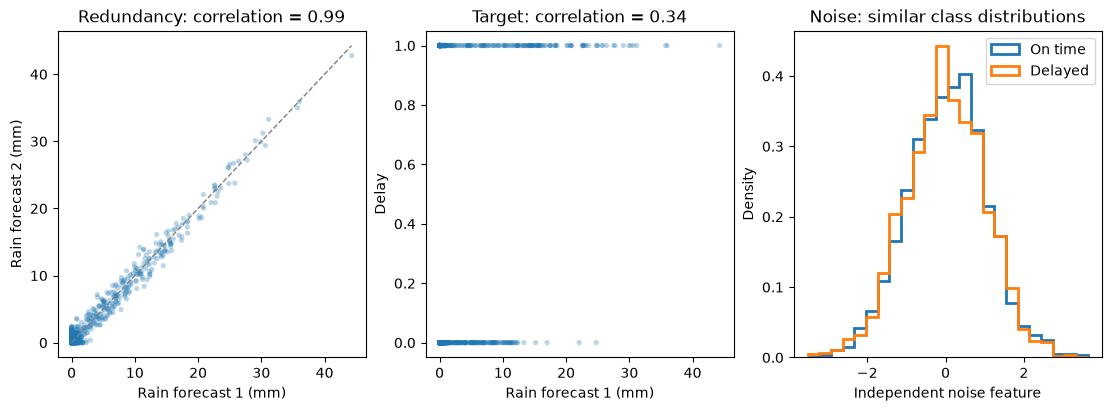

In [6]:
#| echo: false
#| out-height: "400px"
forecast_sample = X.sample(n=min(800, len(X)), random_state=RANDOM_STATE)
y_sample = y.loc[forecast_sample.index]
fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout='constrained')
axes[0].scatter(forecast_sample['weather_rain1'], forecast_sample['weather_rain2'], s=14, alpha=0.3, color='tab:blue', edgecolors='none')
forecast_limit = forecast_sample[['weather_rain1', 'weather_rain2']].to_numpy().max()
axes[0].plot([0, forecast_limit], [0, forecast_limit], '--', color='gray', linewidth=1)
axes[0].set(xlabel='Rain forecast 1 (mm)', ylabel='Rain forecast 2 (mm)', title=f'Redundancy: correlation = {X.weather_rain1.corr(X.weather_rain2):.2f}')
axes[1].scatter(forecast_sample['weather_rain1'], y_sample, s=14, alpha=0.3, color='tab:blue', edgecolors='none')
axes[1].set(xlabel='Rain forecast 1 (mm)', ylabel='Delay', title=f'Target: correlation = {X.weather_rain1.corr(y_sample):.2f}')
noise_bins = np.linspace(X['noise_1'].min(), X['noise_1'].max(), 25)
for label, name, color in [(0, 'On time', 'tab:blue'), (1, 'Delayed', 'tab:orange')]:
    axes[2].hist(X.loc[y.eq(label), 'noise_1'], bins=noise_bins, density=True, histtype='step', linewidth=2, label=name, color=color)
axes[2].set(xlabel='Independent noise feature', ylabel='Density', title='Noise: similar class distributions')
axes[2].legend()
plt.show()


# Is there any reason to discard a feature before training a model?

:::{.fragment}
- IDs. *Why*?
- Sensitive information. *Why*?
- Features that are not available at prediction time. *Why*?
- ...
:::

# Manual feature engineering

Create features from scheduled times and airport codes:

- `departure_hour`, `day_of_week`, `month`, `is_holiday`: scheduled date/time decomposition.
- `airport_*`: fixed airport-presence indicators for airports appearing in either origin or destination.
- Other?


In [7]:
df[['scheduled_departure']].head(n=3)

,scheduled_departure
0,2025-02-02 04:15:00
1,2025-10-10 00:10:00
2,2025-08-27 15:30:00


In [8]:
df[['origin', 'destination']].head(n=3)

,origin,destination
0,ATL,SFO
1,JFK,LAX
2,JFK,BOS


In [9]:
#| echo: false
# Define a sklearn-compatible transformer so feature engineering is fitted inside pipelines.
class FlightFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, add_manual_features=True, include_actual_times=False, drop_datetime=True):
        self.add_manual_features = add_manual_features
        self.include_actual_times = include_actual_times
        self.drop_datetime = drop_datetime

    def fit(self, X, y=None):
        airports = pd.unique(pd.concat([X["origin"], X["destination"]], ignore_index=True))
        self.airport_categories_ = sorted(airports)
        return self

    def transform(self, X):
        X_out = X.copy()
        scheduled_departure = pd.to_datetime(X_out["scheduled_departure"])
        scheduled_arrival = pd.to_datetime(X_out["scheduled_arrival"])
        if self.include_actual_times:
            actual_departure = pd.to_datetime(X_out["actual_departure"])
            actual_arrival = pd.to_datetime(X_out["actual_arrival"])
            X_out["actual_departure_hour"] = actual_departure.dt.hour
            X_out["actual_arrival_hour"] = actual_arrival.dt.hour
            X_out["actual_departure_delay_min"] = (actual_departure - scheduled_departure).dt.total_seconds() / 60
            X_out["actual_arrival_delay_min"] = (actual_arrival - scheduled_arrival).dt.total_seconds() / 60
            X_out["actual_elapsed_min"] = (actual_arrival - actual_departure).dt.total_seconds() / 60

        if self.add_manual_features:
            X_out["departure_hour"] = scheduled_departure.dt.hour
            X_out["day_of_week"] = scheduled_departure.dt.dayofweek
            X_out["month"] = scheduled_departure.dt.month
            X_out["is_weekend"] = X_out["day_of_week"].isin([5, 6]).astype(int)
            X_out["is_holiday"] = (scheduled_departure.dt.normalize().isin(HOLIDAYS) | scheduled_departure.dt.dayofweek.eq(6)).astype(int)

            for airport in self.airport_categories_:
                X_out[f"airport_{airport}"] = ((X_out["origin"] == airport) | (X_out["destination"] == airport)).astype(int)

        if self.drop_datetime:
            datetime_columns = ["scheduled_departure", "scheduled_arrival", "actual_departure", "actual_arrival"]
            X_out = X_out.drop(columns=datetime_columns, errors="ignore")
        return X_out


# Add domain features to reveal patterns

In [10]:
df[['scheduled_departure', 'departure_hour', 'is_holiday', 'is_late_night', 'delayed_15_min']].head(n=3)

,scheduled_departure,departure_hour,is_holiday,is_late_night,delayed_15_min
0,2025-02-02 04:15:00,4,1,1,1
1,2025-10-10 00:10:00,0,0,1,0
2,2025-08-27 15:30:00,15,0,0,1


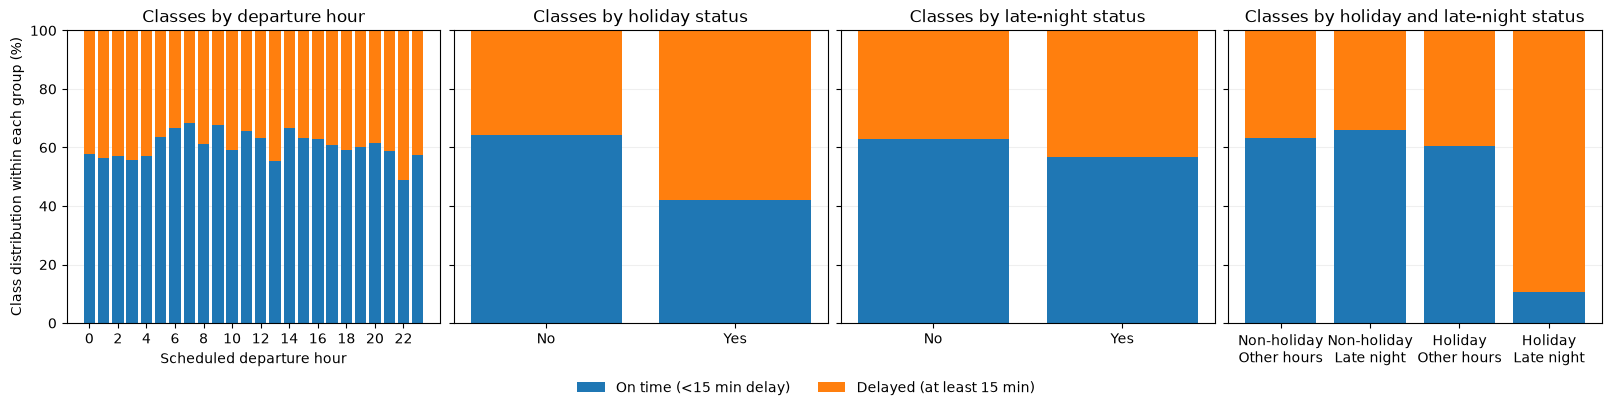

In [11]:
#| echo: false
#| out-height: "400px"

# Normalize within each group to compare class distributions despite unequal group sizes.
hourly_classes = pd.crosstab(df['departure_hour'], df['delayed_15_min']).reindex(
    index=range(24), columns=[0, 1], fill_value=0,
)
is_holiday_classes = pd.crosstab(df['is_holiday'], df['delayed_15_min']).reindex(
    index=range(2), columns=[0, 1], fill_value=0,
)
is_late_night_classes = pd.crosstab(df['is_late_night'], df['delayed_15_min']).reindex(
    index=range(2), columns=[0, 1], fill_value=0,
)
interaction_classes = pd.crosstab(
    [df['is_holiday'], df['is_late_night']], df['delayed_15_min'],
).reindex(
    index=pd.MultiIndex.from_product([[0, 1], [0, 1]], names=['is_holiday', 'is_late_night']),
    columns=[0, 1], fill_value=0,
)
hourly_shares = hourly_classes.div(hourly_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
is_holiday_shares = is_holiday_classes.div(is_holiday_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
is_late_night_shares = is_late_night_classes.div(is_late_night_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
interaction_shares = interaction_classes.div(interaction_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True, layout='constrained')
for ax, shares in zip(axes, [hourly_shares, is_holiday_shares, is_late_night_shares, interaction_shares]):
    positions = np.arange(len(shares))
    ax.bar(positions, shares[0], color='tab:blue', label='On time (<15 min delay)')
    ax.bar(positions, shares[1], bottom=shares[0], color='tab:orange', label='Delayed (at least 15 min)')
    ax.set(ylim=(0, 100))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)

axes[0].set(xlabel='Scheduled departure hour', ylabel='Class distribution within each group (%)', title='Classes by departure hour', xticks=range(0, 24, 2))
interaction_labels = ['Non-holiday\nOther hours', 'Non-holiday\nLate night', 'Holiday\nOther hours', 'Holiday\nLate night']
axes[1].set(xticks=range(2), xticklabels=["No", "Yes"], title='Classes by holiday status')
axes[2].set(xticks=range(2), xticklabels=["No", "Yes"], title='Classes by late-night status')
axes[3].set(xticks=range(4), xticklabels=interaction_labels, title='Classes by holiday and late-night status')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=2, frameon=False)
plt.show()


# Data understanding and visualization

In [12]:
#| echo: false
import seaborn as sns

def check_correlations(X, y, include_actual_times=True, thr=0.6):
    # Combine engineered X and target y
    df_corr = pd.concat(
        [
            FlightFeatureEngineer(
                add_manual_features=True,
                include_actual_times=include_actual_times,
                drop_datetime=False,
            ).fit_transform(X),
            y,
        ],
        axis=1,
    )

    # Convert datetime columns to Unix timestamps in seconds
    for col in df_corr.select_dtypes(include=["datetime", "datetime64"]).columns:
        df_corr[col] = df_corr[col].astype("int64") // 10**9

    # Compute correlation matrix
    corr = df_corr.corr(numeric_only=True)

    # Ignore identity correlations
    non_identity = ~np.eye(len(corr), dtype=bool)

    # Keep variables with at least one non-identity |correlation| > thr
    keep = (corr.abs().gt(thr) & non_identity).any(axis=1)

    keep.loc[y.name] = True
    filtered_corr = corr.loc[keep, keep]

    plt.figure(figsize=(12, 9))
    sns.heatmap(
        filtered_corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        linewidths=0.5,
    )
    plt.title(f"Variables with at least one |correlation| > {thr}")
    plt.tight_layout()
    plt.show()


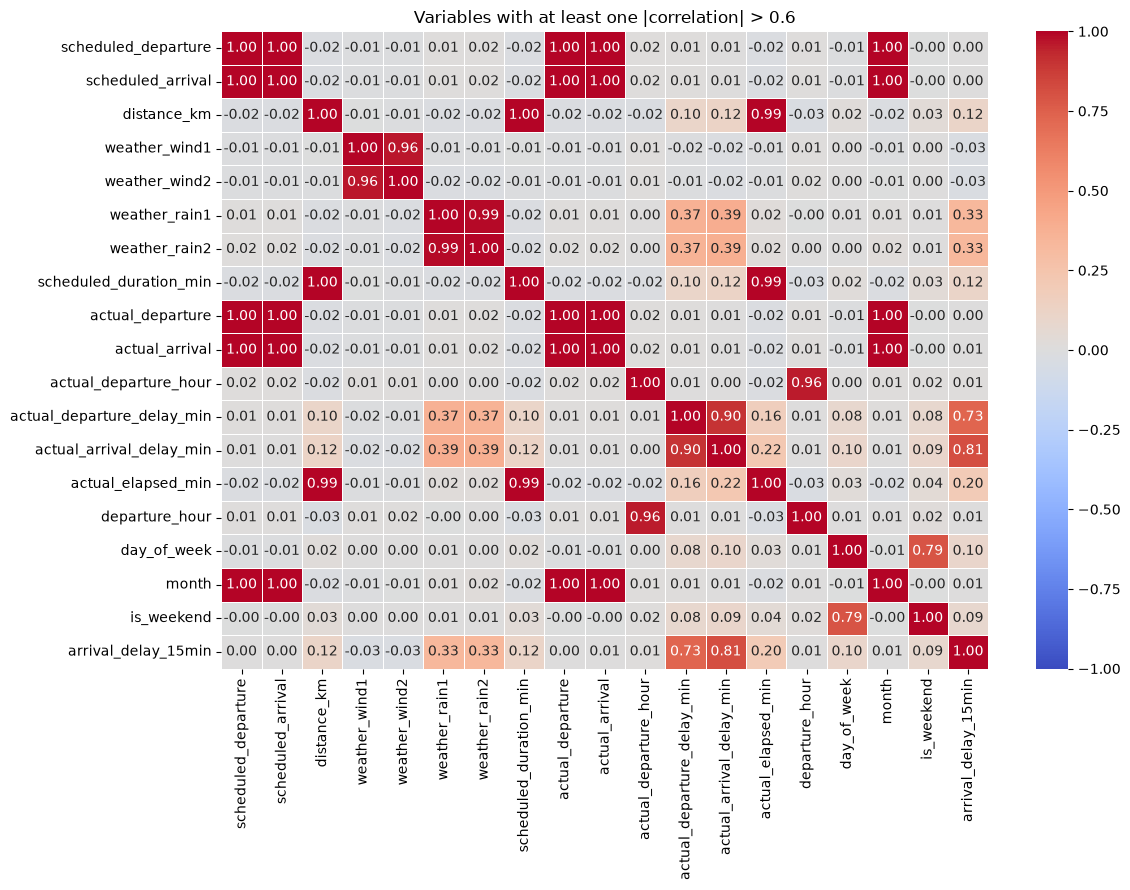

In [13]:
#| echo: false

check_correlations(X, y)

# Data understanding and visualization

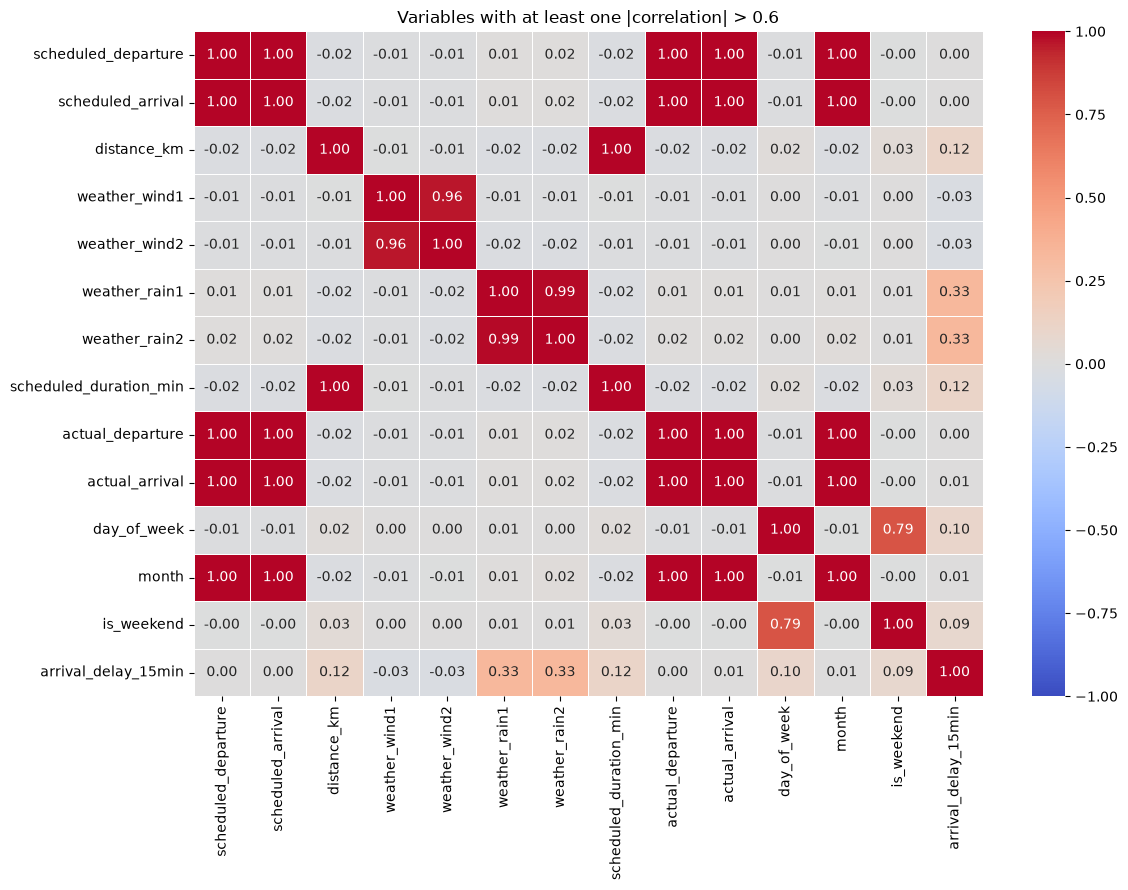

In [14]:
#| echo: false

check_correlations(X, y, include_actual_times=False)

# Are features known at prediction time?


In [15]:
#| echo: false
# Show only the schema fields used in the raw/engineered feature tables.
leaky_engineered_view = FlightFeatureEngineer(
    add_manual_features=True, include_actual_times=True,
).fit_transform(X)
availability_notes = {
    "actual_departure": "after departure", "actual_arrival": "after arrival",
    "actual_departure_hour": "after departure", "actual_arrival_hour": "after arrival",
    "actual_departure_delay_min": "after departure",
    "actual_arrival_delay_min": "after arrival", "actual_elapsed_min": "after arrival",
}
schema_display_columns = ["feature", "dtype", "source", "availability"]
feature_schema = pd.DataFrame([
    {"feature": column,
     "dtype": str(X[column].dtype if column in X else leaky_engineered_view[column].dtype),
     "source": "raw" if column in X else "engineered",
     "availability": availability_notes.get(column, "before departure")}
    for column in dict.fromkeys([*X.columns, *leaky_engineered_view.columns])
])
feature_schema.loc[feature_schema["source"] == "raw"].sort_values(
    by=["availability", "source"], ascending=False,
)


,feature,dtype,source,availability
0,scheduled_departure,datetime64[us],raw,before departure
1,scheduled_arrival,datetime64[us],raw,before departure
2,carrier,str,raw,before departure
3,origin,str,raw,before departure
4,destination,str,raw,before departure
5,distance_km,int64,raw,before departure
6,weather_wind1,float64,raw,before departure
7,weather_wind2,float64,raw,before departure
8,weather_rain1,float64,raw,before departure
9,weather_rain2,float64,raw,before departure


# Are features known at prediction time?

In [16]:
#| echo: false
feature_schema.loc[feature_schema["source"] == "engineered", schema_display_columns].sort_values(by=["availability", "source"], ascending=False)

,feature,dtype,source,availability
21,departure_hour,int32,engineered,before departure
22,day_of_week,int32,engineered,before departure
23,month,int32,engineered,before departure
24,is_weekend,int64,engineered,before departure
25,is_holiday,int64,engineered,before departure
26,airport_ATL,int64,engineered,before departure
27,airport_BOS,int64,engineered,before departure
28,airport_JFK,int64,engineered,before departure
29,airport_LAX,int64,engineered,before departure
30,airport_SFO,int64,engineered,before departure


# Pipeline generation

In [17]:
#| echo: false
# Build reusable preprocessing and classifier helpers for the later experiments.
def make_preprocessor():
    return ColumnTransformer([
        ("num", "passthrough", make_column_selector(dtype_include=np.number)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         make_column_selector(dtype_exclude=np.number)),
    ], verbose_feature_names_out=False)


def make_tree(max_depth=5, min_samples_leaf=1):
    return DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, class_weight="balanced", random_state=RANDOM_STATE)

def mutual_info_reproducible(X_array, y_array):
    return mutual_info_classif(X_array, y_array, random_state=RANDOM_STATE)


def make_pipeline(add_manual_features=False, include_actual_times=False, selector=None):
    steps = [
        ("feature_engineering", FlightFeatureEngineer(add_manual_features=add_manual_features, include_actual_times=include_actual_times)),
        ("preprocessing", make_preprocessor().set_output(transform="pandas")
            if isinstance(selector, Pipeline) else make_preprocessor()),
    ]
    if selector is not None:
        steps.append(("feature_selection", selector))
    steps.append(("classifier", make_tree()))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"balanced_accuracy": "balanced_accuracy", "f1": "f1"}
make_pipeline(add_manual_features=False)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,add_manual_features,False
,include_actual_times,False
,drop_datetime,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be for

# Actual departure and arrival times: keep or drop?

Prediction time matters:

- *Ticket sale*: route, carrier, scheduled times, and planned distance/duration.
- *Morning of travel*: forecasts and known schedule pressure.
- *Gate before departure*: current weather and operational status that is already known.
- *After departure*: actual departure time and departure delay may be inferred.
- *After landing*: actual arrival time and arrival delay are known.


In [18]:
#| echo: false
# Demonstrate how future information can inflate validation metrics.
leakage_demo = {
    "Raw data - no feature engineering": make_pipeline(add_manual_features=False),
    "Feature engineering": make_pipeline(add_manual_features=True),
    "Leaky feature engineering": make_pipeline(add_manual_features=True, include_actual_times=True),
}
leakage_rows = []
for name, estimator in leakage_demo.items():
    result = cross_validate(estimator, X, y, cv=cv, scoring=scoring, n_jobs=-1,)
    leakage_rows.append({
        "experiment": name,
        "balanced_accuracy_mean": result["test_balanced_accuracy"].mean(),
        "f1_mean": result["test_f1"].mean(),
    })


pd.DataFrame(leakage_rows)


,experiment,balanced_accuracy_mean,f1_mean
0,Raw data - no feature engineering,0.757822,0.702689
1,Feature engineering,0.790393,0.745900
2,Leaky feature engineering,1.000000,1.000000


# Coding break 1: Exercises 1-2 (~15 minutes)

<a id="coding-break-1"></a>

First, go to the [exercise setup](#coding-exercise-setup). Run the Bike Sharing download and inspection cells before Exercise 1.

**Go to [Exercises 1-2](#coding-exercises-1).** Prepare the Bike Sharing split, remove leakage columns, and implement cyclic hour features, rush-hour indicators, and working-day interactions.

Stop before Exercise 3. Keep your variables for the next coding break, then [resume theory block 2](#theory-block-2).

Suggested pacing: download, inspect, and split (~4 minutes), implement the cyclic/rush-hour features (~7 minutes), and add interactions and inspect the result (~4 minutes). Reuse the provided plots rather than recreating them.


# Automated feature selection

<a id="theory-block-2"></a>

![Filter Methods](img/remote/filter-methods.png)

**Filter methods** rank features using a statistical criterion independent of the final model [@guyon2003introduction].

- Filter methods are usually faster. *Why?*
- Variance and correlation filters inspect features without using the target.
- We then use mutual information with `SelectKBest`.

# Filter: low variance

`VarianceThreshold` removes features that vary too little in the training data.

```python
from sklearn.feature_selection import VarianceThreshold
variance_filter = VarianceThreshold(threshold=0.01)
```

- `threshold`: discard features with training variance **less than or equal to** this value; the default `0.0` removes constants.
- No target `y` is needed.
- Variance depends on units: do not first scale every feature to unit variance.

[VarianceThreshold API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.VarianceThreshold.html)


# Variance: constant, nearly constant, or varying?

These synthetic features have the same units and mean, but different spreads.


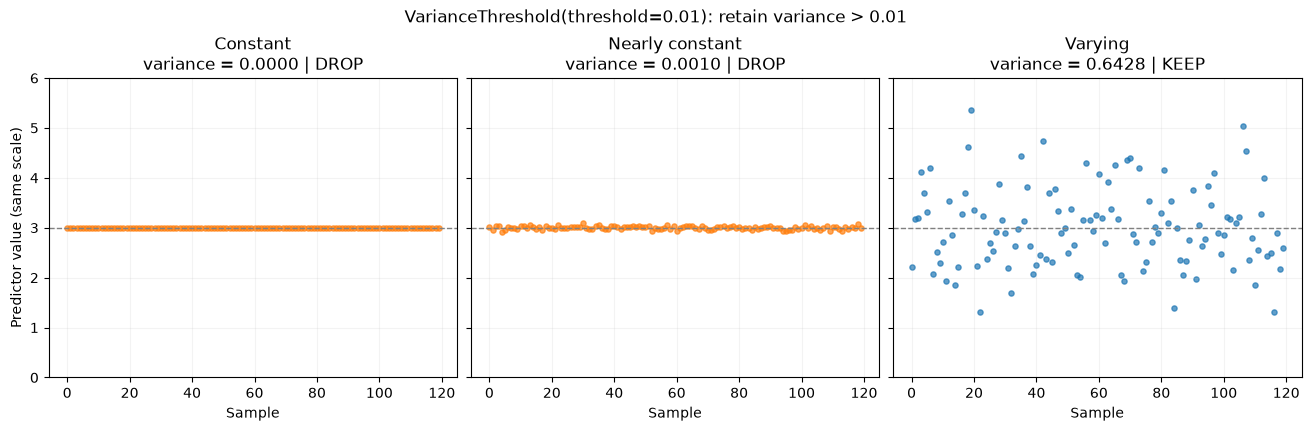

In [ ]:
#| echo: false
#| out-height: "410px"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import VarianceThreshold

variance_demo_rng = np.random.default_rng(42)
variance_demo_X = pd.DataFrame({
    "Constant": np.full(120, 3.0),
    "Nearly constant": 3.0 + variance_demo_rng.normal(0, 0.04, 120),
    "Varying": 3.0 + variance_demo_rng.normal(0, 0.8, 120),
})
# Center all three at the same mean to isolate their different spreads.
variance_demo_X = variance_demo_X - variance_demo_X.mean() + 3.0
variance_demo_filter = VarianceThreshold(threshold=0.01).fit(variance_demo_X)
assert variance_demo_filter.get_support().tolist() == [False, False, True]
np.testing.assert_allclose(
    variance_demo_filter.variances_, variance_demo_X.var(ddof=0),
)
variance_demo_fig, variance_demo_axes = plt.subplots(
    1, 3, figsize=(13, 4.2), sharex=True, sharey=True, layout="constrained",
)
for variance_demo_index, (variance_demo_name, variance_demo_ax) in enumerate(
    zip(variance_demo_X.columns, variance_demo_axes)
):
    variance_demo_keep = variance_demo_filter.get_support()[variance_demo_index]
    variance_demo_ax.scatter(
        np.arange(len(variance_demo_X)), variance_demo_X[variance_demo_name],
        s=14, alpha=0.7, color="tab:blue" if variance_demo_keep else "tab:orange",
    )
    variance_demo_ax.axhline(3.0, color="gray", linestyle="--", linewidth=1)
    variance_demo_ax.set(
        xlabel="Sample", ylim=(0, 6),
        title=f"{variance_demo_name}\nvariance = "
              f"{variance_demo_filter.variances_[variance_demo_index]:.4f}"
              + (" | KEEP" if variance_demo_keep else " | DROP"),
    )
    variance_demo_ax.grid(alpha=0.15)
variance_demo_axes[0].set_ylabel("feature value (same scale)")
variance_demo_fig.suptitle("VarianceThreshold(threshold=0.01): retain variance > 0.01")
plt.show()


# Variance filter: inspect the removals

In [20]:
#| echo: false
from sklearn.feature_selection import VarianceThreshold
filter_plot_train, _, filter_plot_y, _ = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE,
)
filter_preprocessing = make_pipeline(add_manual_features=True)[:-1]
filter_values = filter_preprocessing.fit_transform(filter_plot_train, filter_plot_y)
filter_features = pd.DataFrame(
    filter_values, index=filter_plot_train.index,
    columns=filter_preprocessing.named_steps["preprocessing"].get_feature_names_out(),
)
variance_filter = VarianceThreshold(threshold=0.01).fit(filter_features)
variance_example = pd.DataFrame({"training_variance": variance_filter.variances_, "retained": variance_filter.get_support(),}, index=filter_features.columns)
print(f"Input features: {filter_features.shape[1]}; retained: {variance_filter.get_support().sum()} (threshold=0.01).")
variance_example.sort_values("training_variance").head().round(4)


Input features: 34; retained: 34 (threshold=0.01).


,training_variance,retained
is_holiday,0.1375,True
origin_SFO,0.1532,True
destination_ATL,0.1557,True
carrier_B6,0.1562,True
carrier_DL,0.1574,True


# Filter: high correlation

`DropCorrelatedFeatures` removes redundant numeric features.

```python
from feature_engine.selection import DropCorrelatedFeatures
correlation_filter = DropCorrelatedFeatures(
    variables=None, method="pearson", threshold=0.9,
)
```

- `method="pearson"`: measure linear correlation; `"spearman"` uses ranks.
- `threshold=0.9`: remove a feature if its **absolute** correlation with a retained one exceeds 0.9; the default is 0.8.

[DropCorrelatedFeatures API](https://feature-engine.trainindata.com/en/latest/api_doc/selection/DropCorrelatedFeatures.html)


# Correlation: both positive and negative redundancy

- Keep reference A; compare three other synthetic features with it.
- At `threshold=0.9`, B and C are removed because $|r| > 0.9$; D survives.
- A weak Pearson correlation does not rule out nonlinear dependence.


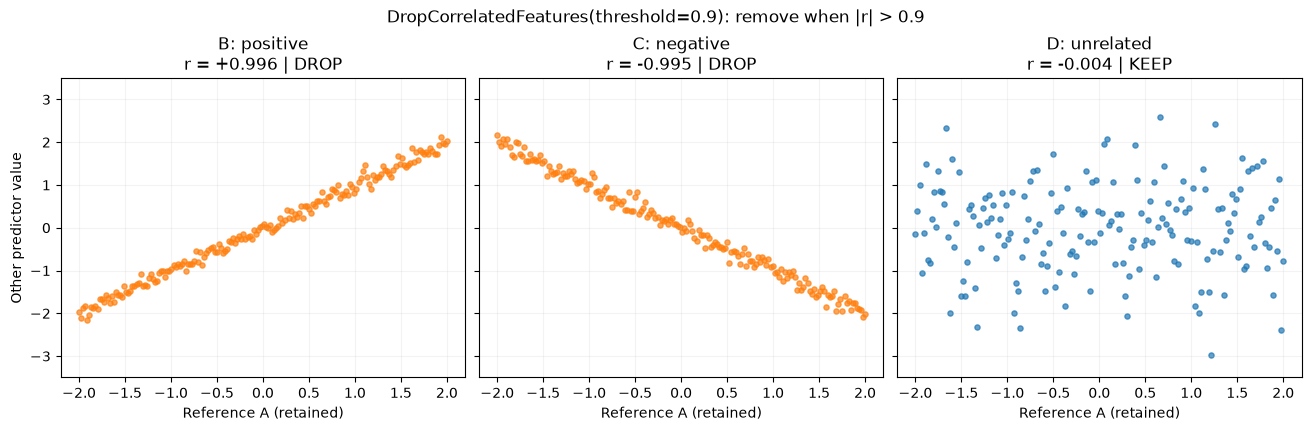

In [ ]:
#| echo: false
#| out-height: "400px"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from feature_engine.selection import DropCorrelatedFeatures

correlation_demo_rng = np.random.default_rng(42)
correlation_demo_reference = np.linspace(-2, 2, 180)
correlation_demo_X = pd.DataFrame({
    "A_reference": correlation_demo_reference,
    "B_positive": correlation_demo_reference + correlation_demo_rng.normal(0, 0.12, 180),
    "C_negative": -correlation_demo_reference + correlation_demo_rng.normal(0, 0.12, 180),
    "D_unrelated": correlation_demo_rng.normal(0, 1.0, 180),
})
correlation_demo_filter = DropCorrelatedFeatures(
    method="pearson", threshold=0.9,
).fit(correlation_demo_X)
assert set(correlation_demo_filter.features_to_drop_) == {"B_positive", "C_negative"}
assert list(correlation_demo_filter.transform(correlation_demo_X)) == ["A_reference", "D_unrelated"]
correlation_demo_fig, correlation_demo_axes = plt.subplots(
    1, 3, figsize=(13, 4.2), sharex=True, sharey=True, layout="constrained",
)
for correlation_demo_name, correlation_demo_ax in zip(
    list(correlation_demo_X.columns)[1:], correlation_demo_axes,
):
    correlation_demo_r = correlation_demo_X["A_reference"].corr(
        correlation_demo_X[correlation_demo_name],
    )
    correlation_demo_drop = correlation_demo_name in correlation_demo_filter.features_to_drop_
    correlation_demo_ax.scatter(
        correlation_demo_reference, correlation_demo_X[correlation_demo_name],
        s=14, alpha=0.7, color="tab:orange" if correlation_demo_drop else "tab:blue",
    )
    correlation_demo_ax.set(
        xlabel="Reference A (retained)", xlim=(-2.2, 2.2), ylim=(-3.5, 3.5),
        title=correlation_demo_name.replace("_", ": ")
              + f"\nr = {correlation_demo_r:+.3f}"
              + (" | DROP" if correlation_demo_drop else " | KEEP"),
    )
    correlation_demo_ax.grid(alpha=0.15)
correlation_demo_axes[0].set_ylabel("Other feature value")
correlation_demo_fig.suptitle("DropCorrelatedFeatures(threshold=0.9): remove when |r| > 0.9")
plt.show()


# Correlation filter: inspect the redundant pairs

In [22]:
#| echo: false


if importlib.util.find_spec("feature_engine") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "feature-engine"])
from feature_engine.selection import DropCorrelatedFeatures

correlation_filter = DropCorrelatedFeatures(threshold=0.9).fit(filter_features)
correlation_example = pd.DataFrame([
    {"retained": kept, "removed": removed,
     "absolute_correlation": abs(filter_features[kept].corr(filter_features[removed]))}
    for kept, redundant in correlation_filter.correlated_feature_dict_.items()
    for removed in sorted(redundant)
])
print(f"Input features: {filter_features.shape[1]}; removed: {len(correlation_filter.features_to_drop_)} (threshold=0.9).")
correlation_example.round(3)


Input features: 34; removed: 3 (threshold=0.9).


,retained,removed,absolute_correlation
0,distance_km,scheduled_duration_min,1.000
1,weather_rain1,weather_rain2,0.989
2,weather_wind1,weather_wind2,0.964


In [23]:
#| echo: false
#| output: false
combined_filters = Pipeline([
    ("variance", VarianceThreshold(threshold=0.01).set_output(transform="pandas")),
    ("correlation", DropCorrelatedFeatures(threshold=0.9)),
])
filtered_feature_train = combined_filters.fit_transform(filter_features)
pd.DataFrame({
    "input_features": [filter_features.shape[1]],
    "after_variance": [len(combined_filters.named_steps["variance"].get_feature_names_out())],
    "after_correlation": [filtered_feature_train.shape[1]],
})


,input_features,after_variance,after_correlation
0,34,34,31


In [24]:
#| echo: false
def make_filter_selector(k):
    return Pipeline([
        *clone(combined_filters).steps,
        ("kbest", SelectKBest(score_func=mutual_info_reproducible, k=k)),
    ])


# Filter: `SelectKBest`

`SelectKBest` ranks features by `score_func` and keeps the top `k`.

```python
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif
mi_score = partial(mutual_info_classif, random_state=42)
filter_selector = SelectKBest(score_func=mi_score, k=8)
```

- Each feature is scored separately: keep the features with the highest estimated mutual information (MI) with the class label.
    - MI is non-negative; zero suggests little dependence between the feature and target.
    - Larger MI means the feature reduces more uncertainty about the label.

- Useful combinations can be missed. *Why?*
- Redundant features can survive. *Why?*


[SelectKBest API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html)

[mutual_info_classif API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html)



In [25]:
#| echo: false

n_features_to_select = 8
filter_selector = make_filter_selector(n_features_to_select)


# What does the filter keep?

- Fit SelectKBest on the features retained by variance and correlation filtering.
    - Color marks retained features; only some features tied at the boundary may be selected.
- These are training scores, not validation performance.


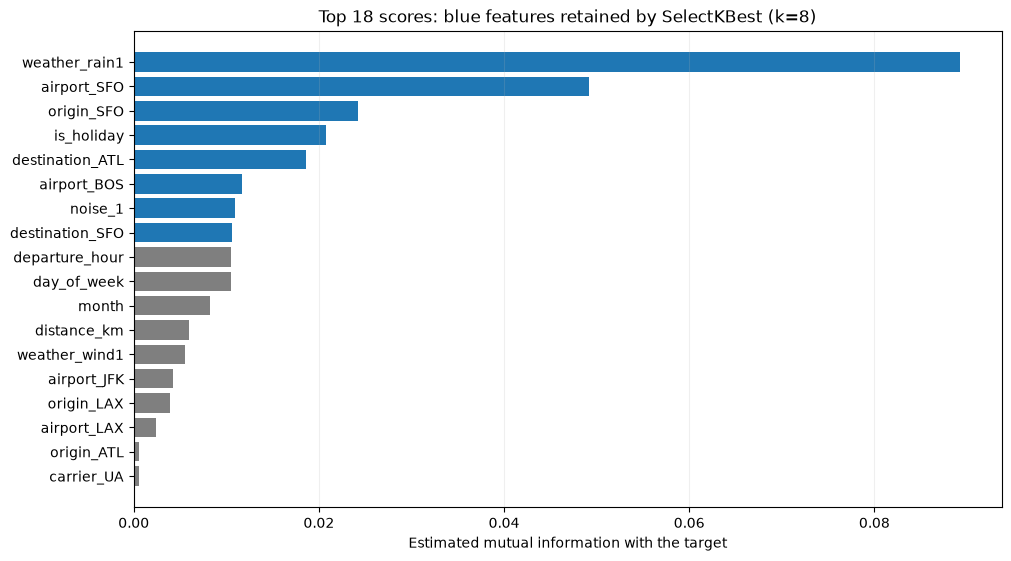

In [26]:
#| echo: false
#| out-height: "400px"

filter_plot_selector = SelectKBest(
    score_func=mutual_info_reproducible, k=n_features_to_select,
).fit(filtered_feature_train, filter_plot_y)
filter_plot_scores = pd.DataFrame({
    'feature': filtered_feature_train.columns,
    'score': filter_plot_selector.scores_,
    'selected': filter_plot_selector.get_support(),
}).sort_values('score', ascending=False).head(18).sort_values('score')
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
ax.barh(filter_plot_scores['feature'], filter_plot_scores['score'],
        color=np.where(filter_plot_scores['selected'], 'tab:blue', 'tab:gray'))
ax.set(xlabel='Estimated mutual information with the target',
       title=f'Top 18 scores: blue features retained by SelectKBest (k={n_features_to_select})')
ax.grid(axis='x', alpha=0.2)
plt.show()


# Compare candidate feature counts `k`

In [27]:
#| echo: false
k_values = np.linspace(5, filtered_feature_train.shape[1], 10, dtype=int)
curve_rows = []
for k in k_values:
    estimator = make_pipeline(add_manual_features=True, selector=make_filter_selector(k),)
    result = cross_validate(estimator, X, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1,)
    curve_rows.append({ "k": k, "balanced_accuracy_mean": result["test_score"].mean(), "balanced_accuracy_std": result["test_score"].std(), })
k_curve = pd.DataFrame(curve_rows)
k_curve


,k,balanced_accuracy_mean,balanced_accuracy_std
0,5,0.716955,0.015365
1,7,0.715234,0.015562
2,10,0.716800,0.015527
3,13,0.749792,0.034429
4,16,0.767447,0.027305
5,19,0.765352,0.026954
6,22,0.771642,0.034421
7,25,0.772301,0.034401
8,28,0.778533,0.028552
9,31,0.789586,0.020354


# Elbow method: choose the "right" `k`.

Choose the point after which extra features give diminishing returns.

- A smaller model may be preferable when its accuracy loss is negligible.

<div></div>

In [28]:
#| echo: false
#| output: false
# Normalize both axes, then find the greatest distance from the endpoint line.
x = k_curve["k"].to_numpy(dtype=float)
y_score = k_curve["balanced_accuracy_mean"].to_numpy(dtype=float)
x_norm = (x - x.min()) / np.ptp(x)
y_norm = (y_score - y_score.min()) / np.ptp(y_score) if np.ptp(y_score) else np.zeros_like(y_score)
endpoint_line = np.interp(x_norm, [0, 1], [y_norm[0], y_norm[-1]])
distances = np.abs(y_norm - endpoint_line) / np.hypot(1, y_norm[-1] - y_norm[0])
elbow_k = int(k_curve.loc[distances.argmax(), "k"])
k_curve.assign(elbow_score=distances).round(3)


,k,balanced_accuracy_mean,balanced_accuracy_std,elbow_score
0,5,0.717,0.015,0.000
1,7,0.715,0.016,0.070
2,10,0.717,0.016,0.136
3,13,0.750,0.034,0.101
4,16,0.767,0.027,0.190
5,19,0.765,0.027,0.089
6,22,0.772,0.034,0.069
7,25,0.772,0.034,0.005
8,28,0.779,0.029,0.026
9,31,0.790,0.020,0.000


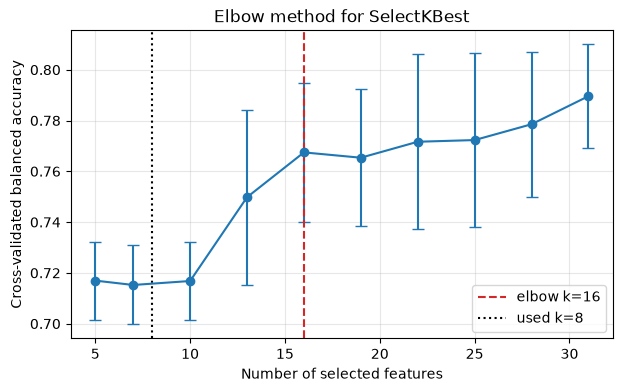

In [29]:
#| echo: false
# Show the elbow curve used to select k.
plt.figure(figsize=(7, 4))
plt.errorbar(k_curve["k"], k_curve["balanced_accuracy_mean"], yerr=k_curve["balanced_accuracy_std"], marker="o", capsize=4)
plt.axvline(elbow_k, color="tab:red", linestyle="--", label=f"elbow k={elbow_k}")
plt.axvline(n_features_to_select, color="black", linestyle=":", label=f"used k={n_features_to_select}")
plt.xlabel("Number of selected features")
plt.ylabel("Cross-validated balanced accuracy")
plt.title("Elbow method for SelectKBest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Coding break 2: Exercises 3-4 (~15 minutes)

<a id="coding-break-2"></a>

**Go to [Exercises 3-4](#coding-exercises-2).** Inspect training variances and correlations (~5 minutes), complete the filter pipeline (~6 minutes), and compare it with the provided raw/engineered baselines (~4 minutes).

Stop before Exercise 5. Keep your variables for the next coding break, then [resume theory block 3](#theory-block-3).


# Automated feature selection

<a id="theory-block-3"></a>

![Wrapper Methods](img/remote/wrapper-methods.png)

**Wrapper methods** search for a subset by repeatedly fitting a model [@guyon2003introduction].

- Wrapper methods can capture model-specific usefulness, but they are more computationally expensive. *Why?*
- Here we use `SequentialFeatureSelector` and `RFE`.

# Wrapper: `SequentialFeatureSelector`

Forward-SFS greedily adds one feature at a time.

- Start with no features.
    - Fit an estimator on each candidate feature and compare cross-validated scores.
    - Keep the best candidate.
- Repeat with each remaining feature added to the selected set.
    - Stop at the desired feature count.

Backward-SFS reverses the search.

- Start with all features and remove one at each step.
- In sklearn, use `SequentialFeatureSelector(direction="backward")`.


# Python: `SequentialFeatureSelector`

```python
from sklearn.feature_selection import SequentialFeatureSelector
sfs_selector = SequentialFeatureSelector(
    estimator=make_tree(), n_features_to_select=8,
    direction="forward", scoring="balanced_accuracy", cv=3, n_jobs=-1,
)
```

- `estimator`: an unfitted model to refit on each candidate subset.
- `n_features_to_select`: desired count, or a fraction between 0 and 1. Default `"auto"` selects half when `tol=None`.
- `direction`: `"forward"` adds features; `"backward"` removes them.
- `scoring` and `cv`: criterion to maximize and the folds used to compare subsets; `cv=3` uses three folds.
- `n_jobs=-1`: use all available processors for CV.

[SequentialFeatureSelector API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html)


In [30]:
#| echo: false

sfs_selector = SequentialFeatureSelector(estimator=make_tree(), n_features_to_select=n_features_to_select, direction="forward", scoring="balanced_accuracy", cv=3, n_jobs=-1)


# SFS: three runs, keeping 1, 2, then 3 features

- Use a depth-2 tree, and five CV folds.
- Try every possible feature addition; keep the one with the highest CV balanced accuracy.


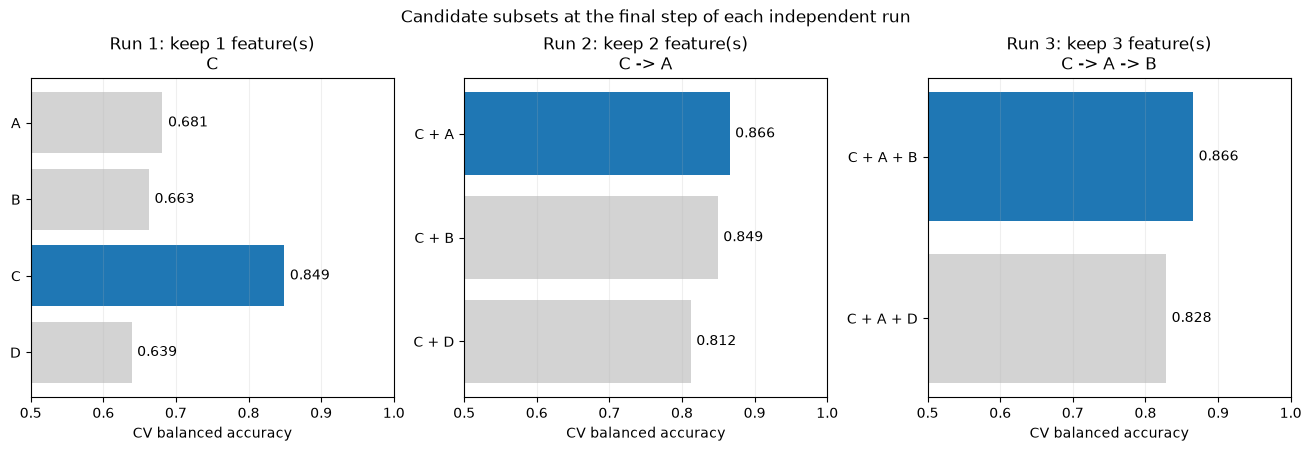

In [31]:
#| echo: false
#| out-height: "430px"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import SequentialFeatureSelector, RFE

# Small synthetic example: four numeric features; no preprocessing is needed.
selection_demo_values, selection_demo_y = make_classification(
    n_samples=240, n_features=4, n_informative=3, n_redundant=1,
    flip_y=0.08, class_sep=0.8, random_state=22,
)
selection_demo_X = pd.DataFrame(selection_demo_values, columns=list("ABCD"))
selection_demo_cv = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42,
).split(selection_demo_X, selection_demo_y))
selection_demo_tree = DecisionTreeClassifier(
    max_depth=2, min_samples_leaf=10, random_state=0,
)

def selection_demo_score(columns):
    return cross_val_score(
        selection_demo_tree, selection_demo_X[columns], selection_demo_y,
        cv=selection_demo_cv, scoring="balanced_accuracy", n_jobs=1,
    ).mean()

selection_demo_runs = []
selection_demo_fig, selection_demo_axes = plt.subplots(
    1, 3, figsize=(13, 4.4), layout="constrained", sharex=True,
)
for selection_demo_keep, selection_demo_ax in enumerate(selection_demo_axes, start=1):
    # Restart from empty for each run, tracing all its greedy additions.
    selection_demo_selected = []
    selection_demo_path = []
    for selection_demo_step in range(selection_demo_keep):
        selection_demo_candidates = [
            feature for feature in selection_demo_X if feature not in selection_demo_selected
        ]
        selection_demo_scores = [
            selection_demo_score(selection_demo_selected + [feature])
            for feature in selection_demo_candidates
        ]
        selection_demo_winner = int(np.argmax(selection_demo_scores))
        selection_demo_labels = [
            " + ".join(selection_demo_selected + [feature])
            for feature in selection_demo_candidates
        ]
        selection_demo_selected.append(selection_demo_candidates[selection_demo_winner])
        selection_demo_path.append(selection_demo_selected[-1])

    # Verify that the explicit search reproduces sklearn's selector.
    selection_demo_sfs = SequentialFeatureSelector(
        selection_demo_tree, n_features_to_select=selection_demo_keep,
        direction="forward", cv=selection_demo_cv,
        scoring="balanced_accuracy", n_jobs=1,
    ).fit(selection_demo_X, selection_demo_y)
    assert set(selection_demo_X.columns[selection_demo_sfs.get_support()]) == set(selection_demo_selected)
    selection_demo_runs.append({
        "run": selection_demo_keep,
        "addition_order": " -> ".join(selection_demo_path),
        "selected": selection_demo_selected.copy(),
        "cv_score": selection_demo_scores[selection_demo_winner],
    })
    selection_demo_bars = selection_demo_ax.barh(
        selection_demo_labels, selection_demo_scores,
        color=["tab:blue" if i == selection_demo_winner else "lightgray"
               for i in range(len(selection_demo_scores))],
    )
    selection_demo_ax.bar_label(selection_demo_bars, fmt="%.3f", padding=4)
    selection_demo_ax.invert_yaxis()
    selection_demo_ax.set(
        xlim=(0.5, 1.0), xlabel="CV balanced accuracy",
        title=f"Run {selection_demo_keep}: keep {selection_demo_keep} feature(s)\n"
              + " -> ".join(selection_demo_path),
    )
    selection_demo_ax.grid(axis="x", alpha=0.2)
selection_demo_fig.suptitle("Candidate subsets at the final step of each independent run")
plt.show()


# Wrapper: `RFE`

Recursive feature elimination (RFE) repeatedly fits an estimator and removes its least important features [@guyon2002gene].

- The estimator must expose feature weights or importances.
    - A linear model can provide coefficients.
    - A tree can provide feature importances.
- Fit the estimator on the current feature set.
    - Remove the least important features, then fit again.
    - Stop at the desired feature count.


# Python: `RFE`

```python
from sklearn.feature_selection import RFE
rfe_selector = RFE(
    estimator=make_tree(), n_features_to_select=8,
    step=0.2, importance_getter="auto",
)
```

- `estimator`: an unfitted model exposing coefficients or feature importances.
- `n_features_to_select=8`: stop with eight features; default `None` keeps half. A fraction specifies a share of inputs.
- `step`: an integer removes that many features per iteration; `0.2` removes 20% of the initial count, rounded down with a minimum of one.

[RFE API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html)


In [32]:
#| echo: false

rfe_selector = RFE(estimator=make_tree(), n_features_to_select=n_features_to_select, step=0.2)

# RFE versus backward SFS

`RFE` and backward `SequentialFeatureSelector` both remove features until the desired subset size is reached.

- **RFE** uses the fitted estimator's importance signal.
    - Logistic regression usually uses coefficient magnitudes; trees use feature importances.
    - It asks: *which feature does the fitted model consider weakest?*

- **Backward `SequentialFeatureSelector` (SFS)** compares candidate removals using balanced accuracy.
    - Remove the feature that gives the best cross-validated score or hurts it least.
    - It asks: *which feature can I remove while preserving validation performance?*
- RFE is usually faster.
    - Backward SFS is usually more expensive because it directly evaluates candidate subsets.


# One fitted tree: what would RFE remove?

- Fit a depth-2 tree on all four features from the SFS example.
- Tree importances measure the total weighted impurity reduction from its splits.
- **B is unused (importance 0), so RFE removes B first** (`step=1`).

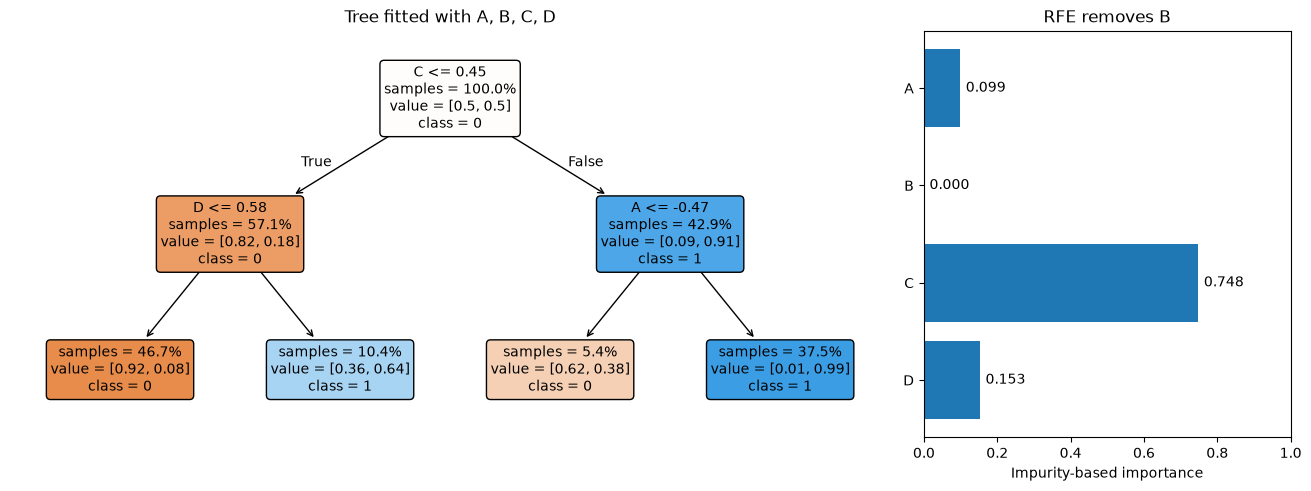

In [33]:
#| echo: false
#| out-height: "440px"

selection_demo_full_tree = DecisionTreeClassifier(
    max_depth=2, min_samples_leaf=10, random_state=0,
).fit(selection_demo_X, selection_demo_y)
selection_demo_importances = selection_demo_full_tree.feature_importances_
selection_demo_rfe = RFE(
    selection_demo_tree, n_features_to_select=3, step=1,
).fit(selection_demo_X, selection_demo_y)
selection_demo_rfe_removed = selection_demo_X.columns[~selection_demo_rfe.get_support()][0]
assert selection_demo_rfe_removed == "B"

selection_demo_fig, selection_demo_axes = plt.subplots(
    1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2.4, 1]},
    layout="constrained",
)
plot_tree(
    selection_demo_full_tree, feature_names=list(selection_demo_X.columns),
    class_names=["0", "1"], filled=True, rounded=True,
    impurity=False, proportion=True, precision=2, fontsize=10,
    ax=selection_demo_axes[0],
)
selection_demo_axes[0].set_title("Tree fitted with A, B, C, D")
selection_demo_bars = selection_demo_axes[1].barh(
    list(selection_demo_X.columns), selection_demo_importances,
    color=["tab:orange" if feature == selection_demo_rfe_removed else "tab:blue"
           for feature in selection_demo_X],
)
selection_demo_axes[1].bar_label(selection_demo_bars, fmt="%.3f", padding=4)
selection_demo_axes[1].invert_yaxis()
selection_demo_axes[1].set(
    xlim=(0, 1), xlabel="Impurity-based importance", title="RFE removes B",
)
plt.show()


# Backward elimination: refit after every candidate removal

- Same data, depth-2 tree; keep three of the four features.
- **Backward SFS** for each possible removal, refit the tree inside each fold and score its validation data.
    - *Removes D*: its removal gives the highest CV balanced accuracy.
- **RFE** removes *B* and keeps *A, C, D*.


In [34]:
#| echo: false

selection_demo_baseline = selection_demo_score(list(selection_demo_X.columns))
selection_demo_removals = pd.DataFrame([
    {
        "Remove": feature,
        "Tree importance": selection_demo_importances[index],
        "CV after removal": selection_demo_score([
            candidate for candidate in selection_demo_X if candidate != feature
        ]),
    }
    for index, feature in enumerate(selection_demo_X)
])
selection_demo_backward = SequentialFeatureSelector(
    selection_demo_tree, n_features_to_select=3, direction="backward",
    cv=selection_demo_cv, scoring="balanced_accuracy", n_jobs=1,
).fit(selection_demo_X, selection_demo_y)
selection_demo_backward_removed = selection_demo_X.columns[
    ~selection_demo_backward.get_support()
][0]
assert selection_demo_backward_removed == "D"
assert selection_demo_removals.loc[
    selection_demo_removals["CV after removal"].idxmax(), "Remove"
] == selection_demo_backward_removed
selection_demo_removals["Change vs. all four"] = (
    selection_demo_removals["CV after removal"] - selection_demo_baseline
)
selection_demo_removals["RFE choice"] = np.where(
    selection_demo_removals["Remove"] == selection_demo_rfe_removed, "remove", "",
)
selection_demo_removals["Backward SFS choice"] = np.where(
    selection_demo_removals["Remove"] == selection_demo_backward_removed, "remove", "",
)
print(f"All four features: CV balanced accuracy = {selection_demo_baseline:.3f}")
selection_demo_removals.round(3)


All four features: CV balanced accuracy = 0.828


,Remove,Tree importance,CV after removal,Change vs. all four,RFE choice,Backward SFS choice
0,A,0.099,0.812,-0.016,,
1,B,0.000,0.828,0.000,remove,
2,C,0.748,0.807,-0.021,,
3,D,0.153,0.866,0.037,,remove


# Compare raw, engineered, and selected feature sets

In [35]:
#| echo: false
# Run every feature strategy under the same stratified cross-validation protocol.

experiments = {
    "raw": make_pipeline(add_manual_features=False),
    "fe": make_pipeline(add_manual_features=True),
    "fe + wrapper (SFS)": make_pipeline(add_manual_features=True, selector=sfs_selector),
    "fe + filter (SelectKBest)": make_pipeline(add_manual_features=True, selector=filter_selector),
    "fe + wrapper (RFE)": make_pipeline(add_manual_features=True, selector=rfe_selector),
}


def selected_feature_names_ordered(fitted_pipeline):
    """Return feature names in the exact order seen by the final estimator."""
    names = fitted_pipeline.named_steps["preprocessing"].get_feature_names_out()
    selector = fitted_pipeline.named_steps.get("feature_selection")
    if selector is None:
        return list(names)
    return list(selector.get_feature_names_out(names))


def mean_jaccard(selected_sets):
    return np.mean([len(a & b) / len(a | b) for a, b in combinations(selected_sets, 2)])


rows = []
selected_sets_by_name = {}

for name, estimator in experiments.items():
    start_time = time.perf_counter()
    result = cross_validate(estimator, X, y, cv=cv, scoring=scoring, return_estimator=True, n_jobs=-1)
    elapsed = time.perf_counter() - start_time

    selected_lists = [selected_feature_names_ordered(fitted) for fitted in result["estimator"]]
    selected_counts = [len(names) for names in selected_lists]
    selected_sets = [set(names) for names in selected_lists]
    selected_sets_by_name[name] = selected_sets
    selector_was_used = "feature_selection" in estimator.named_steps
    stability_jaccard = mean_jaccard(selected_sets) if selector_was_used else np.nan

    rows.append({
        "experiment": name,
        "balanced_accuracy_mean": result["test_balanced_accuracy"].mean(),
        "balanced_accuracy_std": result["test_balanced_accuracy"].std(),
        "f1_mean": result["test_f1"].mean(),
        "f1_std": result["test_f1"].std(),
        "selection_stability_jaccard": stability_jaccard,
        "features_mean": np.mean(selected_counts),
        "features_std": np.std(selected_counts),
        "fit_time_total_sec": elapsed,
    })

summary = pd.DataFrame(rows).sort_values("balanced_accuracy_mean", ascending=False)
summary_by_name = summary.set_index("experiment")
summary


,experiment,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std,selection_stability_jaccard,features_mean,features_std,fit_time_total_sec
4,fe + wrapper (RFE),0.791320,0.019498,0.747075,0.023555,0.911111,8.0,0.0,0.210421
2,fe + wrapper (SFS),0.790923,0.020552,0.746319,0.024987,0.447273,8.0,0.0,9.006556
1,fe,0.790393,0.020539,0.745900,0.024867,NaN,34.0,0.0,0.106373
0,raw,0.757822,0.021924,0.702689,0.027983,NaN,24.0,0.0,0.094202
3,fe + filter (SelectKBest),0.715054,0.015554,0.669056,0.018518,0.393939,8.0,0.0,0.517593


# Compare predictive performance and complexity

- All strategies use the same cross-validation folds.
    - Error bars show the standard deviation across folds, not confidence intervals.
- Compare feature count and fit time alongside accuracy (measured times depend on the machine).


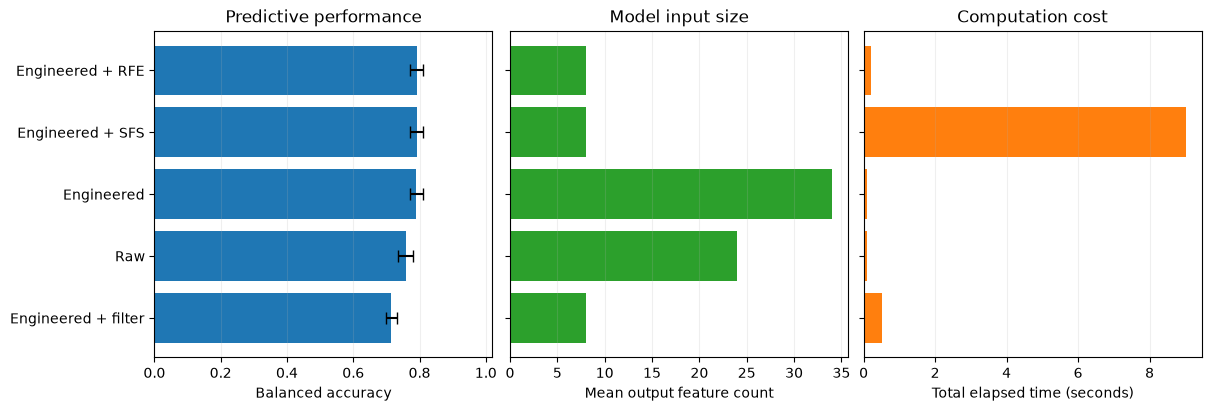

In [36]:
#| echo: false
#| out-height: "400px"

comparison_plot = summary_by_name
strategy_labels = comparison_plot.index.map({
    'raw': 'Raw', 'fe': 'Engineered',
    'fe + wrapper (SFS)': 'Engineered + SFS',
    'fe + filter (SelectKBest)': 'Engineered + filter',
    'fe + wrapper (RFE)': 'Engineered + RFE',
})
positions = np.arange(len(strategy_labels))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout='constrained')
axes[0].barh(positions, comparison_plot['balanced_accuracy_mean'],
                 xerr=comparison_plot['balanced_accuracy_std'], capsize=4, color='tab:blue')
axes[0].set(yticks=positions, yticklabels=strategy_labels, xlim=(0, 1.02),
            xlabel='Balanced accuracy', title='Predictive performance')
axes[0].invert_yaxis()
axes[1].barh(positions, comparison_plot['features_mean'], color='tab:green')
axes[1].set(xlabel='Mean output feature count', title='Model input size')
axes[2].barh(positions, comparison_plot['fit_time_total_sec'], color='tab:orange')
axes[2].set(xlabel='Total elapsed time (seconds)', title='Computation cost')
for ax in axes:
    ax.grid(axis='x', alpha=0.2)
plt.show()


# Selection stability across folds

If selected features change across folds, avoid drawing firm conclusions about which features matter.


In [37]:
#| echo: false
# Show which selected-feature methods are stable across validation folds.
stability_rows = []
for name, selected_sets in selected_sets_by_name.items():
    if "+" not in name:
        continue
    stability_rows.append({
        "experiment": name,
        "mean_jaccard_similarity": summary_by_name.loc[name, "selection_stability_jaccard"],
        "example_selected_features": sorted(selected_sets[0])[:15],
    })

stability = pd.DataFrame(stability_rows).sort_values("mean_jaccard_similarity", ascending=False)
stability


,experiment,mean_jaccard_similarity,example_selected_features
2,fe + wrapper (RFE),0.911111,"[airport_SFO, departure_hour, distance_km, is_..."
0,fe + wrapper (SFS),0.447273,"[airport_JFK, airport_SFO, carrier_B6, departu..."
1,fe + filter (SelectKBest),0.393939,"[airport_ATL, airport_SFO, carrier_AA, day_of_..."


# Do the same features survive each fold?

- Each entry shows the fraction of folds that retained a feature.
    - The chart shows the 18 features selected most often across methods.
- Titles report mean pairwise Jaccard similarity over all selected features.
    - Similar accuracy can come from different subsets.


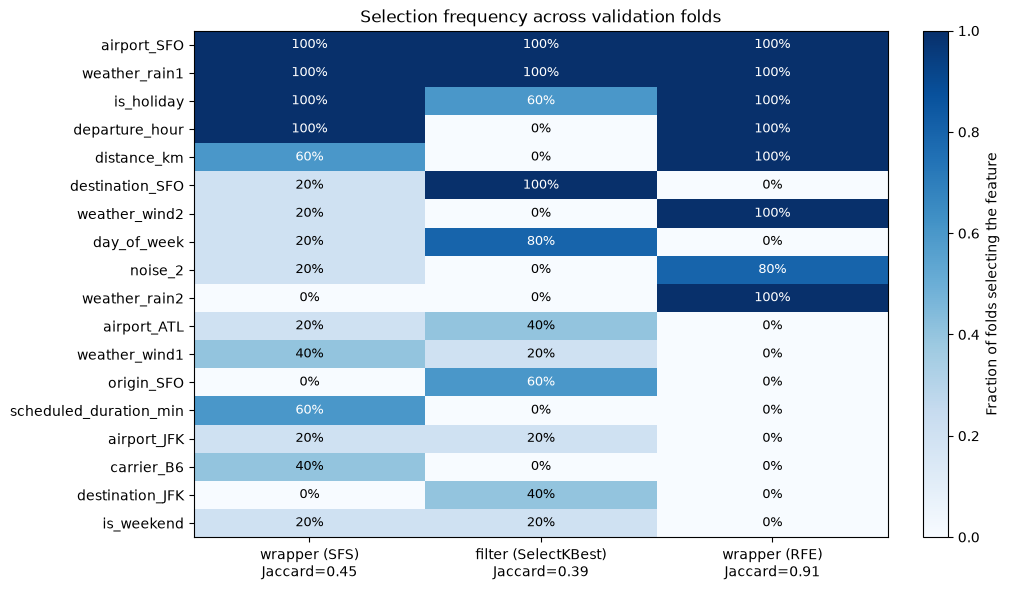

In [38]:
#| echo: false
#| out-height: "400px"

selection_frequency = {}
selection_jaccard = {}
for method, fold_sets in selected_sets_by_name.items():
    if "feature_selection" not in experiments[method].named_steps:
        continue
    selection_frequency[method] = pd.Series({
        feature: np.mean([feature in selected for selected in fold_sets])
        for feature in sorted(set.union(*fold_sets))
    })
    selection_jaccard[method] = summary_by_name.loc[method, "selection_stability_jaccard"]
frequency_plot = pd.DataFrame(selection_frequency).fillna(0)
frequency_features = frequency_plot.mean(axis=1).sort_values(ascending=False, kind='stable').head(18).index
frequency_plot = frequency_plot.loc[frequency_features]
fig, ax = plt.subplots(figsize=(10, 5.8), layout='constrained')
image = ax.imshow(frequency_plot, vmin=0, vmax=1, cmap='Blues', aspect='auto')
for row in range(len(frequency_plot)):
    for col in range(len(frequency_plot.columns)):
        value = frequency_plot.iloc[row, col]
        ax.text(col, row, f'{value:.0%}', ha='center', va='center', fontsize=9,
                color='white' if value > 0.55 else 'black')
ax.set(yticks=range(len(frequency_plot)), yticklabels=frequency_plot.index,
       xticks=range(len(frequency_plot.columns)),
       xticklabels=[f'{name.replace("fe + ", "")}\nJaccard={selection_jaccard[name]:.2f}' for name in frequency_plot.columns],
       title='Selection frequency across validation folds')
fig.colorbar(image, ax=ax, label='Fraction of folds selecting the feature')
plt.show()


# Interpretability check

In [39]:
X_interpret_train, X_interpret_valid, y_interpret_train, y_interpret_valid = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE,)
chosen_pipeline = make_pipeline(add_manual_features=True, selector=rfe_selector)
chosen_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,add_manual_features,True
,include_actual_times,False
,drop_datetime,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be form

# Interpretability check

In [40]:
chosen_pipeline.fit(X_interpret_train, y_interpret_train)
selected_feature_names_for_tree = selected_feature_names_ordered(chosen_pipeline)
tree = chosen_pipeline.named_steps["classifier"]
print("Validation balanced accuracy:", round(balanced_accuracy_score(y_interpret_valid, chosen_pipeline.predict(X_interpret_valid)), 3))
pd.DataFrame({
    "feature": selected_feature_names_for_tree,
    "importance": tree.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

Validation balanced accuracy: 0.776


,feature,importance
0,weather_rain1,0.348670
1,airport_SFO,0.225655
2,distance_km,0.185170
3,departure_hour,0.109938
4,is_holiday,0.087510
5,weather_rain2,0.019028
6,weather_wind2,0.014674
7,noise_3,0.009355


# Plotting the tree

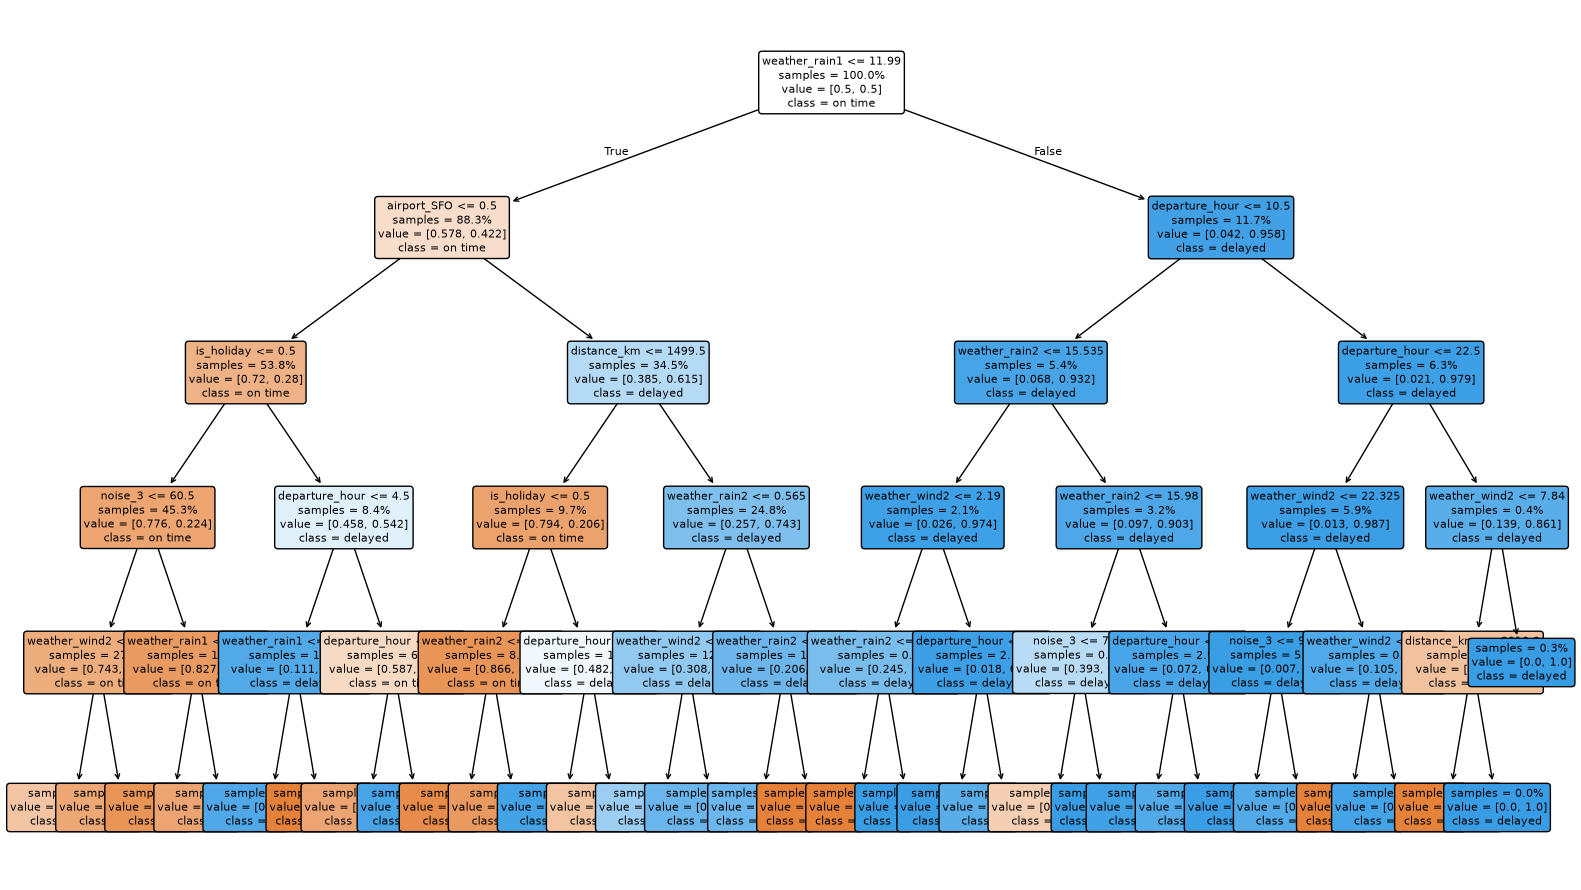

In [41]:
#| echo: false
plt.figure(figsize=(16, 9))
plot_tree(tree, feature_names=selected_feature_names_for_tree, class_names=["on time", "delayed"], filled=True, rounded=True, proportion=True, impurity=False, fontsize=8,)
plt.tight_layout()
plt.show()

# Selected does not always mean used

The tree may ignore some features retained by the selector.

- Zero importance means the fitted tree never split on that feature.


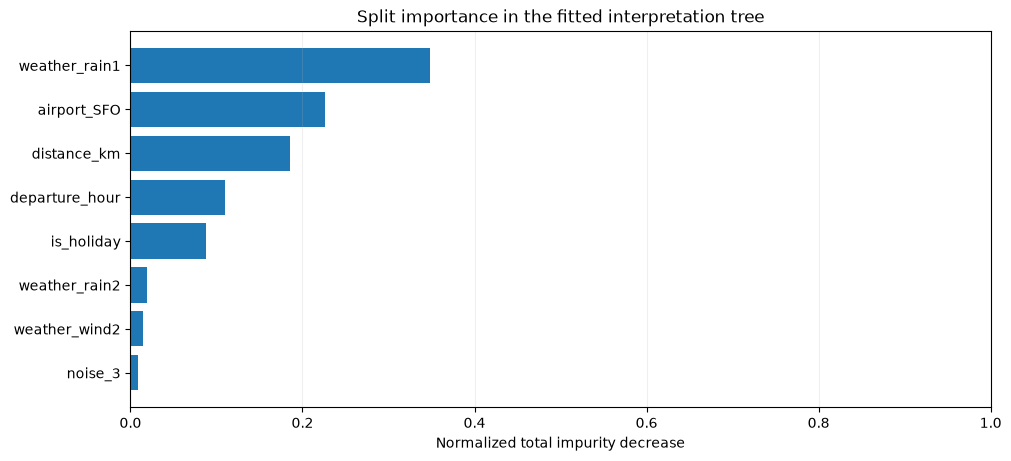

In [42]:
#| echo: false
#| out-height: "400px"

tree_importance_plot = pd.Series(
    tree.feature_importances_, index=selected_feature_names_for_tree,
).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.barh(tree_importance_plot.index, tree_importance_plot.values, color='tab:blue')
ax.set(xlabel='Normalized total impurity decrease', xlim=(0, 1),
       title='Split importance in the fitted interpretation tree')
ax.grid(axis='x', alpha=0.2)
plt.show()


# Permutation importance

How much does validation balanced accuracy fall when we shuffle one feature?

- Positive values indicate that shuffling hurts the score; values near zero indicate little measured effect.

```python
from sklearn.inspection import permutation_importance
importance = permutation_importance(
    tree, X_tree_valid.to_numpy(), y_interpret_valid,
    scoring="balanced_accuracy", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1,
)
```

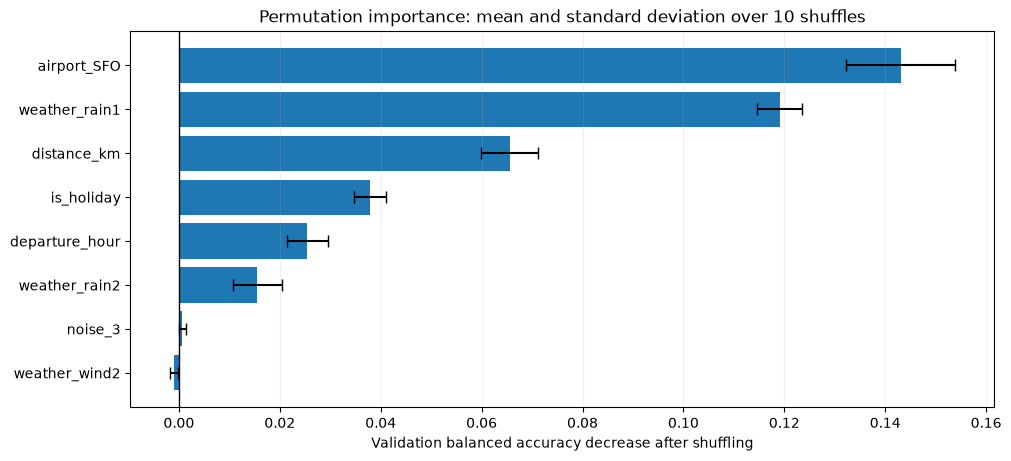

In [43]:
#| echo: false
# Apply every fitted transformation in order, including feature selection.
def tree_input_frame(fitted_pipeline, X_rows):
    values = fitted_pipeline[:-1].transform(X_rows)
    return pd.DataFrame(
        values,
        columns=selected_feature_names_ordered(fitted_pipeline),
        index=X_rows.index,
    )

X_tree_train = tree_input_frame(chosen_pipeline, X_interpret_train)
X_tree_valid = tree_input_frame(chosen_pipeline, X_interpret_valid)
importance = permutation_importance(
    tree, X_tree_valid.to_numpy(), y_interpret_valid,
    scoring="balanced_accuracy", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1,
)
importance_table = pd.DataFrame({
    "tree_feature": selected_feature_names_for_tree,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std,
}).sort_values("importance_mean", ascending=False)
permutation_plot = importance_table.sort_values('importance_mean')
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.barh(permutation_plot['tree_feature'], permutation_plot['importance_mean'],
        xerr=permutation_plot['importance_std'], capsize=4, color='tab:blue')
ax.axvline(0, color='black', linewidth=1)
ax.set(xlabel='Validation balanced accuracy decrease after shuffling',
       title='Permutation importance: mean and standard deviation over 10 shuffles')
ax.grid(axis='x', alpha=0.2)
plt.show()


# [Optional] SHAP: the contribution of each feature

**SHAP** assigns contributions to a prediction [@lundberg2017unified; @lundberg2020local].

For the delayed class (`y=1`), we explain the model's prediction probability: $\hat{P}(y=1 \mid x) = \text{base value} + \sum_{j=1}^{p} \phi_j(x).$

- Positive contributions raise the prediction above the baseline; negative contributions lower it.
- SHAP explains the fitted model, not causal effects.

In [ ]:
#| echo: false

# Install SHAP only if it is missing (also works in Colab).

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap>=0.45"])

import shap

background = X_tree_train.sample(n=min(100, len(X_tree_train)), random_state=RANDOM_STATE) # Use training rows as the background and explain validation rows only.
X_explain = X_tree_valid.sample(n=min(300, len(X_tree_valid)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(
    tree,
    data=background,
    feature_names=selected_feature_names_for_tree,
    feature_perturbation="interventional",
    model_output="probability",
)
all_class_shap = explainer(X_explain)
delayed_class_index = int(np.flatnonzero(tree.classes_ == 1)[0])
shap_delayed = all_class_shap[:, :, delayed_class_index]

delayed_probability = tree.predict_proba(X_explain.to_numpy())[:, delayed_class_index]
np.testing.assert_allclose(shap_delayed.base_values + shap_delayed.values.sum(axis=1), delayed_probability, atol=1e-6,)  # Check that all contributions reconstruct each prediction.
print(f"Explained {len(X_explain)} validation flights and {X_explain.shape[1]} selected features.")

Explained 300 validation flights and 8 selected features.


# [Optional] Global SHAP contributions

Mean absolute SHAP values rank how much features move predictions across the explained flights.

In [46]:
#| echo: false
#| output: false
# Show every selected feature, including zero contributions.
shap_importance = pd.DataFrame({
    "tree_feature": selected_feature_names_for_tree,
    "mean_abs_shap": np.abs(shap_delayed.values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)
shap_importance.round(4)


,tree_feature,mean_abs_shap
2,weather_rain1,0.1281
7,airport_SFO,0.1246
0,distance_km,0.0875
6,is_holiday,0.0465
5,departure_hour,0.0315
3,weather_rain2,0.0279
4,noise_3,0.0178
1,weather_wind2,0.0120


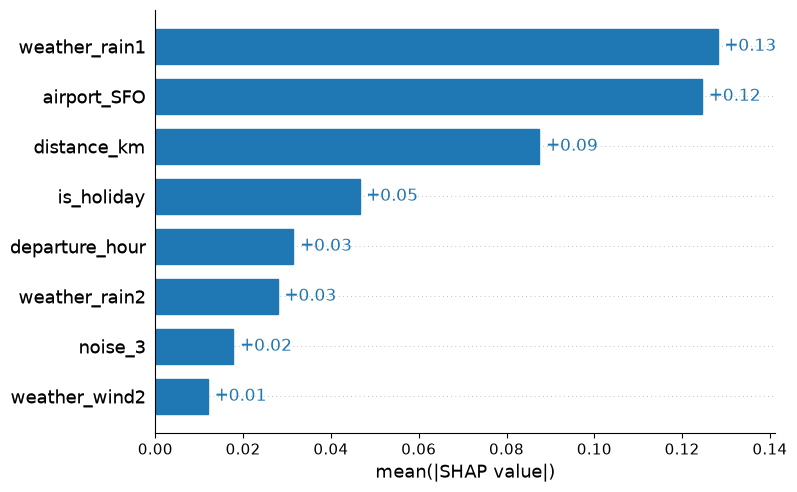

In [47]:
#| echo: false
shap.plots.bar(shap_delayed, max_display=len(selected_feature_names_for_tree), show=False)
for artist in [*plt.gca().patches, *plt.gca().texts]:
    artist.set_color("tab:blue")
plt.show()


# [Optional] Direction and variation across flights

Each dot in the beeswarm plot is a flight.

- Horizontal position shows the signed contribution; color shows the feature value.
- E.g., check the contribution of rain forecasts

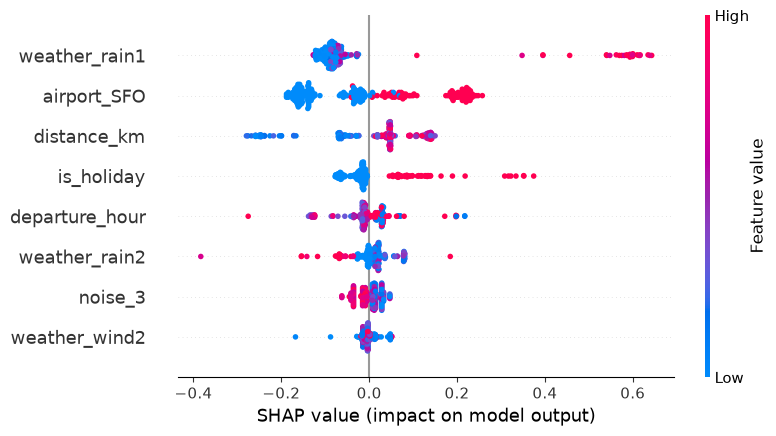

In [48]:
shap.plots.beeswarm(shap_delayed, max_display=len(selected_feature_names_for_tree))

# [Optional] Local SHAP contributions: explain one flight

In [49]:
#| echo: false
#| output: false
flight_position = 0  # Change this to inspect another validation flight.
flight_explanation = shap_delayed[flight_position]


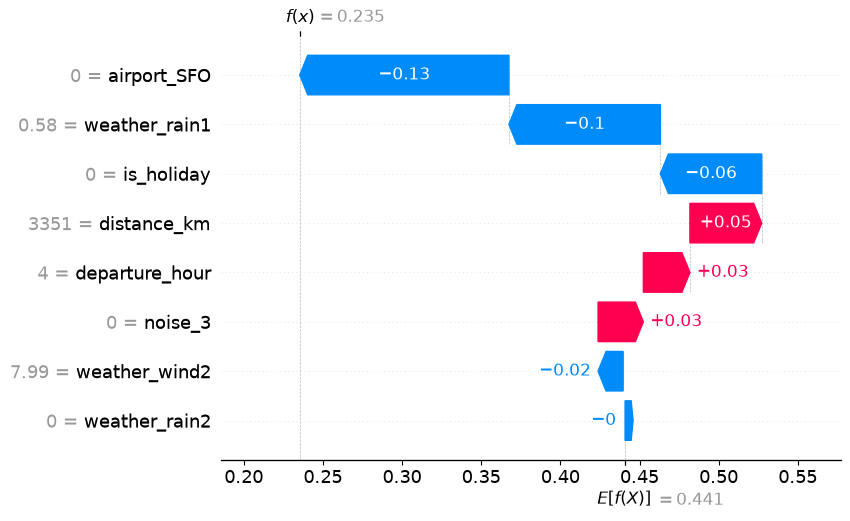

In [50]:
shap.plots.waterfall(flight_explanation, max_display=len(selected_feature_names_for_tree))

Check that the base value plus all signed contributions equals the model's predicted probability.


In [51]:
#| echo: false
pd.DataFrame([{
    "flight_index": X_explain.index[flight_position],
    "base_probability": float(flight_explanation.base_values),
    "sum_of_contributions": float(flight_explanation.values.sum()),
    "reconstructed_probability": float(flight_explanation.base_values + flight_explanation.values.sum()),
    "predicted_probability": delayed_probability[flight_position],
}])


,flight_index,base_probability,sum_of_contributions,reconstructed_probability,predicted_probability
0,3701,0.440884,-0.205538,0.235346,0.235346


# [Optional] Permutation importance vs SHAP

- Permutation importance measures score decrease
- SHAP measures probability-contribution magnitude.

In [52]:
#| echo: false
#| output: false
importance_comparison = importance_table.merge(shap_importance, on="tree_feature")


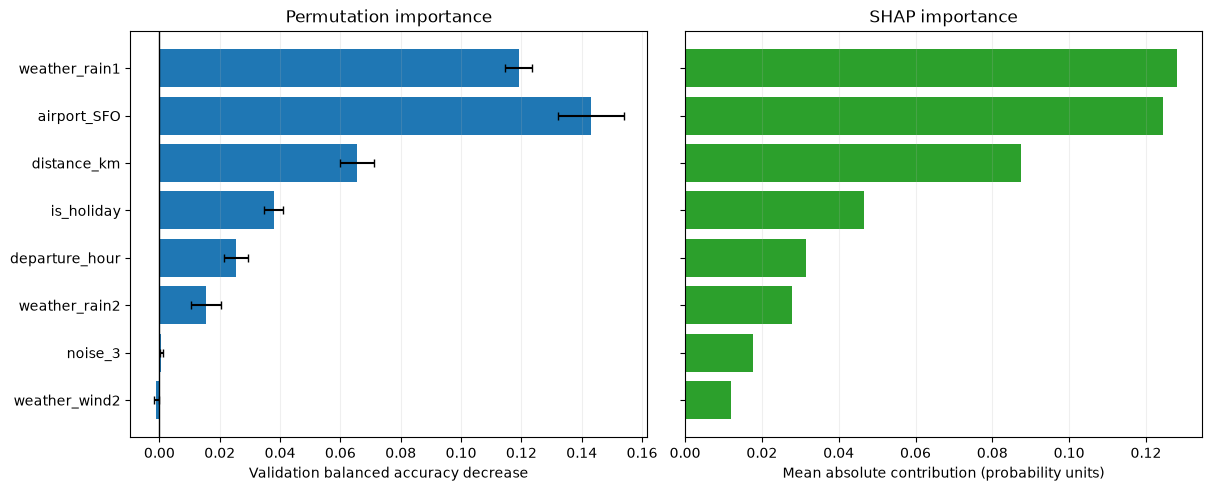

In [53]:
#| echo: false
#| out-height: "400px"

importance_plot = importance_comparison.sort_values('mean_abs_shap')
positions = np.arange(len(importance_plot))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout='constrained')
axes[0].barh(positions, importance_plot['importance_mean'],
             xerr=importance_plot['importance_std'], capsize=3, color='tab:blue')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set(yticks=positions, yticklabels=importance_plot['tree_feature'],
            xlabel='Validation balanced accuracy decrease', title='Permutation importance')
axes[1].barh(positions, importance_plot['mean_abs_shap'], color='tab:green')
axes[1].set(xlabel='Mean absolute contribution (probability units)', title='SHAP importance')
for ax in axes:
    ax.grid(axis='x', alpha=0.2)
plt.show()


# Coding break 3: Exercises 5-6 (~15 minutes)

<a id="coding-break-3"></a>

**Go to [Exercises 5-6](#coding-exercises-3).** Add RFE to the saved comparison (~6 minutes), inspect retained features and tree importances (~5 minutes), and explain the accuracy/complexity tradeoff (~4 minutes).

Use the final minutes to compare results and discuss your explanation.


# Exercise: Bike Sharing

<a id="coding-exercise-setup"></a>

Predict hourly bicycle rentals using the [UCI Bike Sharing dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) [@fanaeet2013bike].

- Compare raw and manually engineered features.
- Compare variance/correlation filters with RFE using a decision tree.
- Use one fixed random 70/30 training/validation split, with no cross-validation.
- Complete the commented cells; the full implementation is under **Exercise solution** near the end of the notebook.


# Download the data

Run the provided code to download `hour.csv` and inspect its first rows.

In [54]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

bike_url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
with ZipFile(BytesIO(urlopen(bike_url).read())) as archive:
    bike_df = pd.read_csv(archive.open("hour.csv"), parse_dates=["dteday"])
bike_df = bike_df.sort_values(["dteday", "hr"]).reset_index(drop=True)
bike_df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# Inspect the data

- `cnt` is the total number of rentals in an hour.
- `casual` and `registered` sum to `cnt`; including them would reveal the answer.

In [55]:
bike_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

# Regression: inspect the distribution of `cnt`.

In [56]:
bike_df["cnt"].describe().round(1)


count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64

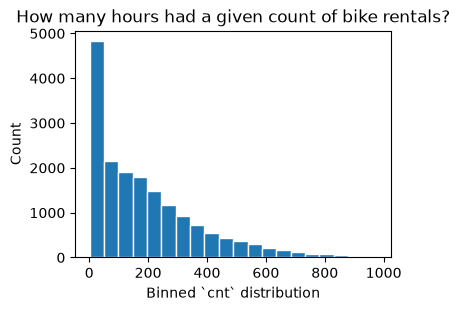

In [57]:
#| echo: false
fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
ax.hist(bike_df["cnt"], bins=20, color="tab:blue", edgecolor="white")
ax.set(xlabel="Binned `cnt` distribution", ylabel="Count", title="How many hours had a given count of bike rentals?")
plt.show()


# Exercise 1: use a fixed random split and manually drop some features

<a id="coding-exercises-1"></a>

- Randomly assign 70% of observations to training and 30% to validation with `random_state=42`.
- Fit feature selection using training rows only.
- Remove the row `ID`, `date` (*why*?), `target`, and the two leakage columns.


In [58]:
bike_X = bike_df # substitute it with bike_df.drop(columns=[???])
bike_y = bike_df["cnt"]
bike_X_train, bike_X_valid, bike_y_train, bike_y_valid = train_test_split(
    bike_X, bike_y, test_size=0.30, random_state=42,
)
bike_tree_params = dict(max_depth=6, min_samples_leaf=20, random_state=42)
print(f"Training: {len(bike_X_train):,} rows; validation: {len(bike_X_valid):,} rows.")


Training: 12,165 rows; validation: 5,214 rows.


# Exercise 2: feature engineering - encode the hour as a cycle

- A tree can learn from `hr` directly; cyclic features may help, but improvement is not guaranteed.
- Hours 23 and 0 are adjacent, but their numeric values are far apart.
- Map hour $h$ onto a circle with $\theta = 2\pi h/24$.
    - Add $\sin(\theta)$ and $\cos(\theta)$; together they identify the hour and preserve wraparound.

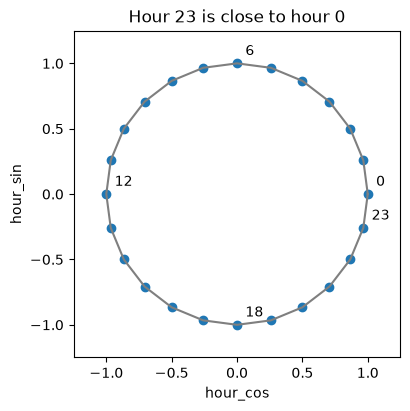

In [59]:
#| echo: false
hours = np.arange(24)
angles = 2 * np.pi * hours / 24
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.plot(np.cos(np.r_[angles, angles[0]]), np.sin(np.r_[angles, angles[0]]), color="tab:gray")
ax.scatter(np.cos(angles), np.sin(angles), color="tab:blue")
for hour in [0, 6, 12, 18, 23]: ax.annotate(str(hour), (np.cos(angles[hour]), np.sin(angles[hour])), xytext=(6, 6), textcoords="offset points")
ax.set(xlabel="hour_cos", ylabel="hour_sin", title="Hour 23 is close to hour 0", aspect="equal", xlim=(-1.25, 1.25), ylim=(-1.25, 1.25))
plt.show()


In [67]:
# Update the function add_bike_features(X).
def add_bike_features(X):
    X = X.copy()
    ...
    return X
# Compute angle = 2 * np.pi * X["hr"] / 24.
# Add to X hour_sin and hour_cos using np.sin(angle) and np.cos(angle).


# Exercise 2: feature engineering - add rush-hour indicators

- Create `morning_rush` for hours 7-9 and `evening_rush` for hours 16-19 (these fixed windows represent a commuting hypothesis).

In [ ]:
# Update the function add_bike_features(X).
# Add to X morning_rush using X["hr"].between(7, 9).astype(int).
# Add to X evening_rush using the inclusive range 16 to 19.


# Exercise 2: feature engineering - add hour by working-day interactions

- The tree can already learn interactions between features; but *explicit features may help a depth-limited tree*.


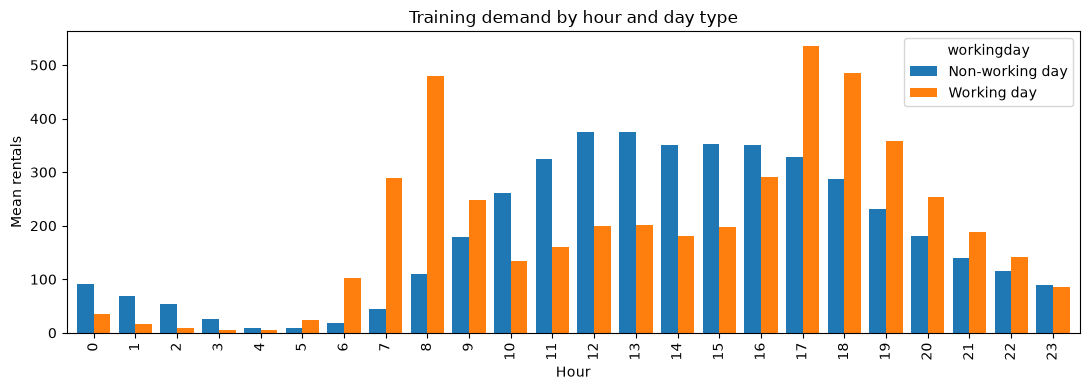

In [60]:
#| echo: false
bike_hourly_train = bike_df.loc[bike_X_train.index].groupby(["hr", "workingday"])["cnt"].mean().unstack()
ax = bike_hourly_train.rename(columns={0: "Non-working day", 1: "Working day"}).plot.bar(
    figsize=(11, 4), color=["tab:blue", "tab:orange"], width=0.8,
)
ax.set(xlabel="Hour", ylabel="Mean rentals", title="Training demand by hour and day type")
plt.tight_layout()
plt.show()


In [68]:
# Update the function add_bike_features(X).
# Add to X hour_workday = hr * workingday.
# Add to X hour_nonworkday = hr * (1 - workingday).

# Apply the function to bike_X_train and bike_X_valid.
# Save bike_X_train_fe and bike_X_valid_fe, then inspect their added columns.


# Resume theory after coding 1

Stop here until the next coding break. Keep your variables and [return to theory block 2](#theory-block-2).


# Exercise 3: inspect training variances

<a id="coding-exercises-2"></a>

- Calculate each engineered feature's variance with `var(ddof=0)` and sort it.
- Which features have the smallest variance? Are any constant?

In [ ]:
# Calculate bike_variances = bike_X_train_fe.var(ddof=0).sort_values().
# Show every feature's variance, rounded to four decimals.
# List features whose variance is <= 0.01: these will be removed.
# Compare windspeed with hr: do their different units explain their variance gap?
# Would converting a feature's units change this filter's decision?


# Exercise 4: inspect training correlations

- Calculate absolute Pearson correlations using `bike_X_train_fe.corr().abs()`.
- Which feature could you drop from each pair?
    - High correlation suggests redundancy; low correlation does not rule out nonlinear dependence.


In [69]:
# Calculate bike_correlations = bike_X_train_fe.corr().abs().
# Show pairs above 0.9 and propose a feature to remove.
# Hint: keep the upper triangle to exclude self-correlations and duplicate pairs.


# Exercise 4: compare trees with and without filters

Run the provided baseline comparison, then complete the filter pipeline for **both raw and engineered inputs**. Keep the split and tree settings fixed. Save the models and scores for coding break 3.

- Chain `VarianceThreshold(0.01)`, `DropCorrelatedFeatures(threshold=0.9)`, and `DecisionTreeRegressor(**bike_tree_params)`.
- Use the provided `record_bike_model` helper to fit each pipeline and record MAE, RMSE, R2, and retained feature count.
- Does filtering change the error or only the number of features?


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
def regression_metrics(y_true, y_pred):
    """Return MAE, RMSE, and R2 for observed and predicted rental counts."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

bike_models, bike_results = {}, []
bike_inputs = {
    "Raw": (bike_X_train, bike_X_valid),
    "Engineered": (bike_X_train_fe, bike_X_valid_fe),
}

def record_bike_model(label, model, train, valid):
    model.fit(train, bike_y_train)
    names = model[:-1].get_feature_names_out(train.columns)
    bike_models[label] = (model, names)
    bike_results.append({"Model": label, **regression_metrics(bike_y_valid, model.predict(valid)),
                         "Features": len(names)})

# Provided baselines: focus your implementation on the filters.
for label, (train, valid) in bike_inputs.items():
    baseline = Pipeline([("selection", "passthrough"), ("tree", DecisionTreeRegressor(**bike_tree_params))])
    record_bike_model(f"{label} + Tree", baseline, train, valid)

# For each label, (train, valid) in bike_inputs.items():
#   Create a fresh Pipeline with variance, correlation, and tree stages.
#   Use record_bike_model(f"{label} + Filters", model, train, valid).
# Display pd.DataFrame(bike_results).set_index("Model").round(3).


# Resume theory after coding 2

Stop here until the next coding break. Keep your variables and [return to theory block 3](#theory-block-3).


# Exercise 5: add RFE to the comparison

<a id="coding-exercises-3"></a>

- For each input representation, chain `RFE(DecisionTreeRegressor(**bike_tree_params), n_features_to_select=8)` and a fresh decision tree.
- Use `record_bike_model` to add both RFE models to the four saved comparisons from coding break 2.
- Compare validation errors and retained feature counts for no selection, filters, and RFE. Keep the same split and tree settings.


In [ ]:
# For each label, (train, valid) in bike_inputs.items():
#   model = Pipeline([
#       ("selection", RFE(DecisionTreeRegressor(**bike_tree_params), n_features_to_select=8)),
#       ("tree", DecisionTreeRegressor(**bike_tree_params)),
#   ])
#   Use record_bike_model(f"{label} + RFE", model, train, valid).
# Display all six comparisons using pd.DataFrame(bike_results).set_index("Model").round(3).


# Exercise 6: explain

- Did cyclic encoding, rush indicators, and interactions improve the tree's validation scores? Support your answer with MAE, RMSE, and R2.
- Compare filtering with no selection on the same inputs: how many features were removed, and how did the errors change?
- Which added features are used by the tree? Nonzero importance alone does not establish a validation improvement.
- Explain why engineering may have little effect when a tree can already learn the same boundaries.

- Compare RFE with the filters at the same input representation: does any error reduction justify the retained feature count?


In [ ]:
# For each label, (model, names) in bike_models.items():
#   Pair model.named_steps["tree"].feature_importances_ with names in a pd.Series.
#   Sort only after pairing each importance with its feature name.
#   A removed feature is absent from names; a retained but unused feature has importance 0.
# Compare engineering with selection fixed, then selection with inputs fixed.
# Explain the validation errors and feature counts in bike_results.


# Exercise Solution

<details>
<summary>Show the solution</summary>

```python
from IPython.display import display
from sklearn.tree import DecisionTreeRegressor

url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
with ZipFile(BytesIO(urlopen(url).read())) as archive:
    bike_df = pd.read_csv(archive.open("hour.csv"), parse_dates=["dteday"])
bike_df = bike_df.sort_values(["dteday", "hr"]).reset_index(drop=True)

X = bike_df.drop(columns=["instant", "dteday", "casual", "registered", "cnt"])
X_train, X_valid, y_train, y_valid = train_test_split(
    X, bike_df["cnt"], test_size=0.3, random_state=42,
)
tree_params = dict(max_depth=6, min_samples_leaf=20, random_state=42)

def add_bike_features(X):
    X = X.copy()
    angle = 2 * np.pi * X["hr"] / 24
    X["hour_sin"], X["hour_cos"] = np.sin(angle), np.cos(angle)
    X["morning_rush"] = X["hr"].between(7, 9).astype(int)
    X["evening_rush"] = X["hr"].between(16, 19).astype(int)
    X["hour_workday"] = X["hr"] * X["workingday"]
    X["hour_nonworkday"] = X["hr"] * (1 - X["workingday"])
    return X

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

X_train_fe, X_valid_fe = add_bike_features(X_train), add_bike_features(X_valid)
variances = X_train_fe.var(ddof=0).sort_values()
display(variances.round(4))
print("Variance <= 0.01:", variances[variances <= 0.01].index.tolist())
correlations = X_train_fe.corr().abs()
pairs = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool)).stack()
display(pairs[pairs > 0.9].sort_values(ascending=False).round(3))

rows, importances = [], {}
for inputs, train, valid in [
    ("Raw", X_train, X_valid), ("Engineered", X_train_fe, X_valid_fe),
]:
    selectors = {
        "Tree": "passthrough",
        "Filters": Pipeline([
            ("variance", VarianceThreshold(0.01).set_output(transform="pandas")),
            ("correlation", DropCorrelatedFeatures(threshold=0.9)),
        ]),
        "RFE": RFE(DecisionTreeRegressor(**tree_params), n_features_to_select=8),
    }
    for method, selector in selectors.items():
        model = Pipeline([
            ("selection", selector), ("tree", DecisionTreeRegressor(**tree_params)),
        ]).fit(train, y_train)
        names = model[:-1].get_feature_names_out(train.columns)
        label = f"{inputs} + {method}"
        rows.append({"Model": label, **regression_metrics(y_valid, model.predict(valid)),
                     "Features": len(names)})
        importances[label] = pd.Series(model.named_steps["tree"].feature_importances_, index=names)

results = pd.DataFrame(rows).set_index("Model").sort_values("RMSE")
display(results.round(3))
display(pd.DataFrame(importances).round(3))
```

</details>


# References